# Bangladesh DHS 2022 | Antenatal care — comprehensive exploratory analysis

**Analytic source:** finalized, pre-split primary master from the locked 15-predictor specification.  
**Unit of analysis:** 5,063 women; three reported ANC-visit groups (0, 1–7, ≥8).  
**Scope:** exploratory descriptions, sampling-weighted distributions, normality diagnostics, predictor dependencies, sparse-cell assessments, subgroup patterns, and mapped division-level outcomes.  
**Statistical note:** weighted point estimates use the processed survey weights. Analytic-sample PSU/stratum Taylor intervals are exploratory approximations; the primary master alone cannot reproduce full original-design domain variances.

## 01 | Dependencies, source path, and analysis directories

In [1]:
# ----------------------------------------------------------------------------------------------
# Analysis libraries and immutable source configuration
# ----------------------------------------------------------------------------------------------
from pathlib import Path
from datetime import datetime, timezone
import os, json, hashlib, math, warnings, unicodedata, urllib.request
from textwrap import fill

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from scipy import stats
from IPython.display import display

try:
    import seaborn as sns
except ImportError:
    sns = None

PRIMARY_FILE = Path(os.environ.get(
    "BDHS_ANC_EDA_PRIMARY_FILE",
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\01_processed_data\FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
))
EDA_ROOT = Path(os.environ.get(
    "BDHS_ANC_EDA_OUTPUT_ROOT", r"E:\BDHS_ANC_EDA_ONLY_2026\FINAL_PROCESSED_MASTER_EDA"
))
OUT = {
    key: EDA_ROOT / key for key in
    ["01_qc", "02_tables", "03_figures", "04_maps", "05_reports", "06_assets"]
}
for folder in OUT.values():
    folder.mkdir(parents=True, exist_ok=True)

EXPECTED_PRIMARY_SHA256 = "0cf7e22a0f8d1f2c4554e96ac56ef6dec6170f9067596519b0dcd1978132283a"
CHECK_HASH = os.environ.get("BDHS_ANC_EDA_VERIFY_HASH", "1") == "1"

def file_hash(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(4 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def save_csv(frame, name, folder="02_tables"):
    if any(c.upper() in {"CASEID", "_ROW_ID"} for c in frame.columns):
        raise ValueError("Individual identifiers must not appear in aggregate output tables.")
    path = OUT[folder] / f"{name}.csv"
    frame.to_csv(path, index=False, encoding="utf-8-sig")
    return path

def save_plot(fig, name, folder="03_figures"):
    fig.savefig(OUT[folder] / f"{name}.png", dpi=230, bbox_inches="tight", facecolor="white")
    fig.savefig(OUT[folder] / f"{name}.pdf", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

def check(condition, message):
    if not bool(condition):
        raise RuntimeError(message)

if sns is not None:
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 230, "axes.titlesize": 12.5,
    "axes.titleweight": "semibold", "axes.labelsize": 10.5, "font.family": "DejaVu Sans",
    "axes.spines.top": False, "axes.spines.right": False,
})
COLORS = {0: "#E27669", 1: "#4B83BF", 2: "#15988C"}
CLASS_TEXT = {0: "No ANC", 1: "1–7 ANC visits", 2: "8+ ANC visits"}
PALETTE = [COLORS[i] for i in range(3)]

print("PROJECT:", EDA_ROOT)
print("SOURCE:", PRIMARY_FILE)
print("NumPy:", np.__version__, "| pandas:", pd.__version__)

PROJECT: E:\BDHS_ANC_EDA_ONLY_2026\FINAL_PROCESSED_MASTER_EDA
SOURCE: E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\01_processed_data\FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv
NumPy: 2.4.6 | pandas: 3.0.3


## 02 | Frozen primary master, predictor dictionary, and QC gate

In [2]:
# ----------------------------------------------------------------------------------------------
# Final primary predictors and analytic-sample verification
# ----------------------------------------------------------------------------------------------
NUMERIC = [
    "maternal_age_at_index_birth_years", "prior_live_births", "household_size_members"
]
ORDINAL = ["maternal_education", "wealth_quintile"]
NOMINAL = [
    "partner_education_primary_final", "division", "pregnancy_intention",
    "healthcare_decision_primary_final"
]
BINARY = [
    "residence", "weekly_media_exposure", "working_status", "religion_final",
    "household_head_sex", "distance_barrier"
]
CATEGORICAL = ORDINAL + NOMINAL + BINARY
PREDICTORS = NUMERIC + CATEGORICAL
ADMIN = ["_ROW_ID", "CASEID", "ANC_VISITS", "ANC_CLASS", "ANC_CLASS_LABEL", "SURVEY_WEIGHT", "PSU", "STRATUM"]
EXPECTED_COLUMNS = ADMIN + PREDICTORS
EXPECTED_CLASS_COUNTS = {0: 403, 1: 4407, 2: 253}

LEVEL_ORDERS = {
    "maternal_education": ["No education", "Primary", "Secondary", "Higher"],
    "wealth_quintile": ["Poorest", "Poorer", "Middle", "Richer", "Richest"],
    "partner_education_primary_final": [
        "No education", "Primary", "Secondary", "Higher",
        "No current partner; partner education unavailable", "Partner education not reported"
    ],
    "division": ["Barishal", "Chattogram", "Dhaka", "Khulna", "Mymensingh", "Rajshahi", "Rangpur", "Sylhet"],
    "pregnancy_intention": ["Wanted then", "Wanted later", "Wanted no more"],
    "healthcare_decision_primary_final": [
        "Respondent alone", "Respondent and husband/partner",
        "Husband/partner alone", "Other decision-maker", "No current partner / not applicable"
    ],
    "residence": ["Urban", "Rural"],
    "weekly_media_exposure": ["No", "Yes"],
    "working_status": ["No", "Yes"],
    "religion_final": ["Islam", "Non-Islam"],
    "household_head_sex": ["Male", "Female"],
    "distance_barrier": ["Not a big problem", "Big problem"],
}

check(PRIMARY_FILE.is_file(), f"Missing processed primary master: {PRIMARY_FILE}")
SOURCE_SHA256 = file_hash(PRIMARY_FILE)
if CHECK_HASH:
    check(SOURCE_SHA256 == EXPECTED_PRIMARY_SHA256,
          f"Processed source hash mismatch. Expected {EXPECTED_PRIMARY_SHA256}; got {SOURCE_SHA256}.")

eda = pd.read_csv(PRIMARY_FILE, dtype={"CASEID": "string"}, low_memory=False)
check(eda.shape == (5063, 23), f"Unexpected finalized dataset shape: {eda.shape}")
check(eda.columns.tolist() == EXPECTED_COLUMNS,
      f"Column sequence differs from frozen primary master.\nObserved: {eda.columns.tolist()}")
check(eda[ADMIN + PREDICTORS].isna().sum().sum() == 0, "Unresolved missing cells detected.")
check(eda["_ROW_ID"].is_unique and eda["CASEID"].is_unique, "Duplicate record identifiers.")

for c in NUMERIC + ["ANC_VISITS", "ANC_CLASS", "SURVEY_WEIGHT"]:
    eda[c] = pd.to_numeric(eda[c], errors="raise")
for c in CATEGORICAL:
    eda[c] = eda[c].astype("string").str.strip()
    actual = set(eda[c].dropna().tolist())
    expected = set(LEVEL_ORDERS[c])
    check(actual == expected, f"Unexpected levels for {c}: missing={expected-actual}, extra={actual-expected}")

eda["ANC_CLASS"] = eda["ANC_CLASS"].astype(int)
check(eda["ANC_CLASS"].value_counts().sort_index().to_dict() == EXPECTED_CLASS_COUNTS,
      "ANC category counts differ from frozen specification.")
check((eda["ANC_VISITS"] >= 0).all(), "ANC count must be non-negative.")
recreated = np.select(
    [eda.ANC_VISITS.eq(0), eda.ANC_VISITS.between(1, 7), eda.ANC_VISITS.ge(8)],
    [0, 1, 2], default=-1
)
check(np.array_equal(recreated, eda.ANC_CLASS.to_numpy()), "ANC outcome values are inconsistent.")
check(eda["PSU"].nunique() == 672 and eda["STRATUM"].nunique() == 16,
      "Processed survey identifiers differ from the finalized master.")
check(len(PREDICTORS) == 15 and len(NUMERIC) == 3 and len(CATEGORICAL) == 12,
      "Predictor dictionary is inconsistent.")
check((eda.SURVEY_WEIGHT > 0).all() and np.isfinite(eda.SURVEY_WEIGHT.to_numpy(float)).all(),
      "Invalid sampling weights.")
check(int((eda["partner_education_primary_final"] == "No current partner; partner education unavailable").sum()) == 47,
      "Partner education structural-availability count changed.")
check(int((eda["partner_education_primary_final"] == "Partner education not reported").sum()) == 9,
      "Partner education non-reporting count changed.")
check(int((eda["healthcare_decision_primary_final"] == "Other decision-maker").sum()) == 174,
      "Healthcare decision grouping count changed.")

w = eda["SURVEY_WEIGHT"].to_numpy(float)
y = eda["ANC_CLASS"].to_numpy(int)
n = len(eda)
NSTRATA = eda.STRATUM.nunique()
NPSU = eda.PSU.nunique()

inventory = pd.DataFrame([
    ["Processed observations", n], ["Processed master columns", eda.shape[1]],
    ["Numeric predictors", len(NUMERIC)], ["Categorical predictors", len(CATEGORICAL)],
    ["Final predictors", len(PREDICTORS)], ["Analytic PSUs", NPSU], ["Analytic strata", NSTRATA],
    ["Missing predictor cells", int(eda[PREDICTORS].isna().sum().sum())],
], columns=["Metric", "Observed"])
save_csv(inventory, "01_processed_master_inventory", "01_qc")
print("DATASET CHECK: PASS |", eda.shape, "| PREDICTORS:", len(PREDICTORS))
print("OUTCOMES:", eda.ANC_CLASS.value_counts().sort_index().to_dict())
display(inventory)

DATASET CHECK: PASS | (5063, 23) | PREDICTORS: 15
OUTCOMES: {0: 403, 1: 4407, 2: 253}


,Metric,Observed
0,Processed observations,5063
1,Processed master columns,23
2,Numeric predictors,3
3,Categorical predictors,12
4,Final predictors,15
5,Analytic PSUs,672
6,Analytic strata,16
7,Missing predictor cells,0


## 03 | Stratified PSU-aware descriptive estimators

Sampling-weighted point estimates refer to the finalized analytic population. Taylor standard errors use the strata and PSUs **present in this processed master**. These intervals are exploratory approximations, not reconstructed full-design domain estimates.

In [3]:
# ----------------------------------------------------------------------------------------------
# Sampling-weighted means, confidence intervals, and subgroup effective sample sizes
# ----------------------------------------------------------------------------------------------
frame = eda[["STRATUM", "PSU"]].copy().astype(str)
frame.columns = ["stratum", "psu"]
frame["psu_key"] = frame.stratum + " | " + frame.psu
clusters, cluster_id = np.unique(frame.psu_key.to_numpy(), return_inverse=True)
stratum_by_cluster = frame.groupby("psu_key", sort=True)["stratum"].first().reindex(clusters)
stratum_codes = stratum_by_cluster.to_numpy()
cluster_groups = {
    key: np.where(stratum_codes == key)[0] for key in sorted(set(stratum_codes))
}
check(len(clusters) == NPSU, "Cluster indexing failed.")
SINGLETON_STRATA = [key for key, ids in cluster_groups.items() if len(ids) < 2]
check(not SINGLETON_STRATA, f"Singleton processed analytic strata: {SINGLETON_STRATA}")
DESIGN_DF = len(clusters) - len(cluster_groups)
TCRIT = float(stats.t.ppf(.975, DESIGN_DF))

# Taylor variance of a weighted mean using the analytic PSU structure.
def weighted_estimate(values, domain=None, interval=True):
    v = np.asarray(values, dtype=float)
    d = np.ones(n, dtype=bool) if domain is None else np.asarray(domain, dtype=bool)
    valid = d & np.isfinite(v)
    denom = w[valid].sum()
    if denom <= 0:
        return dict(N=0, Estimate=np.nan, SE=np.nan, LCL=np.nan, UCL=np.nan,
                    Kish_N=np.nan, PSU_N=0)
    est = float(np.dot(w[valid], v[valid]) / denom)
    psu_n = np.unique(cluster_id[valid]).size
    kish = float(denom**2 / np.square(w[valid]).sum())
    IF = np.zeros(n)
    IF[valid] = w[valid] * (v[valid] - est) / denom
    u = np.bincount(cluster_id, weights=IF, minlength=len(clusters))
    variance = 0.0
    for ids in cluster_groups.values():
        centered = u[ids] - u[ids].mean()
        variance += len(ids) / (len(ids) - 1) * float(np.sum(centered**2))
    se = math.sqrt(max(0.0, variance))
    lcl, ucl = est - TCRIT * se, est + TCRIT * se
    if interval:
        lcl, ucl = max(0.0, lcl), min(1.0, ucl)
    return dict(N=int(valid.sum()), Estimate=est, SE=se, LCL=lcl, UCL=ucl,
                Kish_N=kish, PSU_N=int(psu_n))

def weighted_quantile(x, probs, weights=None):
    xv = np.asarray(x, float)
    wt = w if weights is None else np.asarray(weights, float)
    good = np.isfinite(xv) & np.isfinite(wt) & (wt > 0)
    xv, wt = xv[good], wt[good]
    if len(xv) == 0:
        return np.full(len(np.atleast_1d(probs)), np.nan)
    ix = np.argsort(xv, kind="mergesort")
    xv, wt = xv[ix], wt[ix]
    z = (np.cumsum(wt) - wt / 2) / wt.sum()
    return np.interp(np.atleast_1d(probs), z, xv, left=xv[0], right=xv[-1])

def weighted_correlation(a, b, weights=None):
    x, z = np.asarray(a, float), np.asarray(b, float)
    wt = w if weights is None else np.asarray(weights, float)
    good = np.isfinite(x) & np.isfinite(z) & np.isfinite(wt) & (wt > 0)
    x, z, wt = x[good], z[good], wt[good]
    if not len(x): return np.nan
    mx, mz = np.average(x, weights=wt), np.average(z, weights=wt)
    vx, vz = np.average((x-mx)**2, weights=wt), np.average((z-mz)**2, weights=wt)
    if vx <= 0 or vz <= 0: return np.nan
    return float(np.average((x-mx)*(z-mz), weights=wt) / np.sqrt(vx*vz))

# PSU-influence covariance for a vector of linearized contrasts.
def influence_covariance(matrix):
    influences = np.asarray(matrix, float)
    if influences.ndim == 1: influences = influences[:, None]
    cl = np.column_stack([
        np.bincount(cluster_id, weights=influences[:, j], minlength=len(clusters))
        for j in range(influences.shape[1])
    ])
    result = np.zeros((cl.shape[1], cl.shape[1]))
    for ids in cluster_groups.values():
        tmp = cl[ids] - cl[ids].mean(axis=0)
        result += (len(ids) / (len(ids) - 1)) * (tmp.T @ tmp)
    return result

print(f"Analytic-sample design: {NPSU} PSUs; {NSTRATA} strata; denominator df={DESIGN_DF}")

Analytic-sample design: 672 PSUs; 16 strata; denominator df=656


## 04 | ANC outcome prevalence, visit counts, and survey-weight diagnostics

findfont: Failed to find font weight semibold, now using 700.


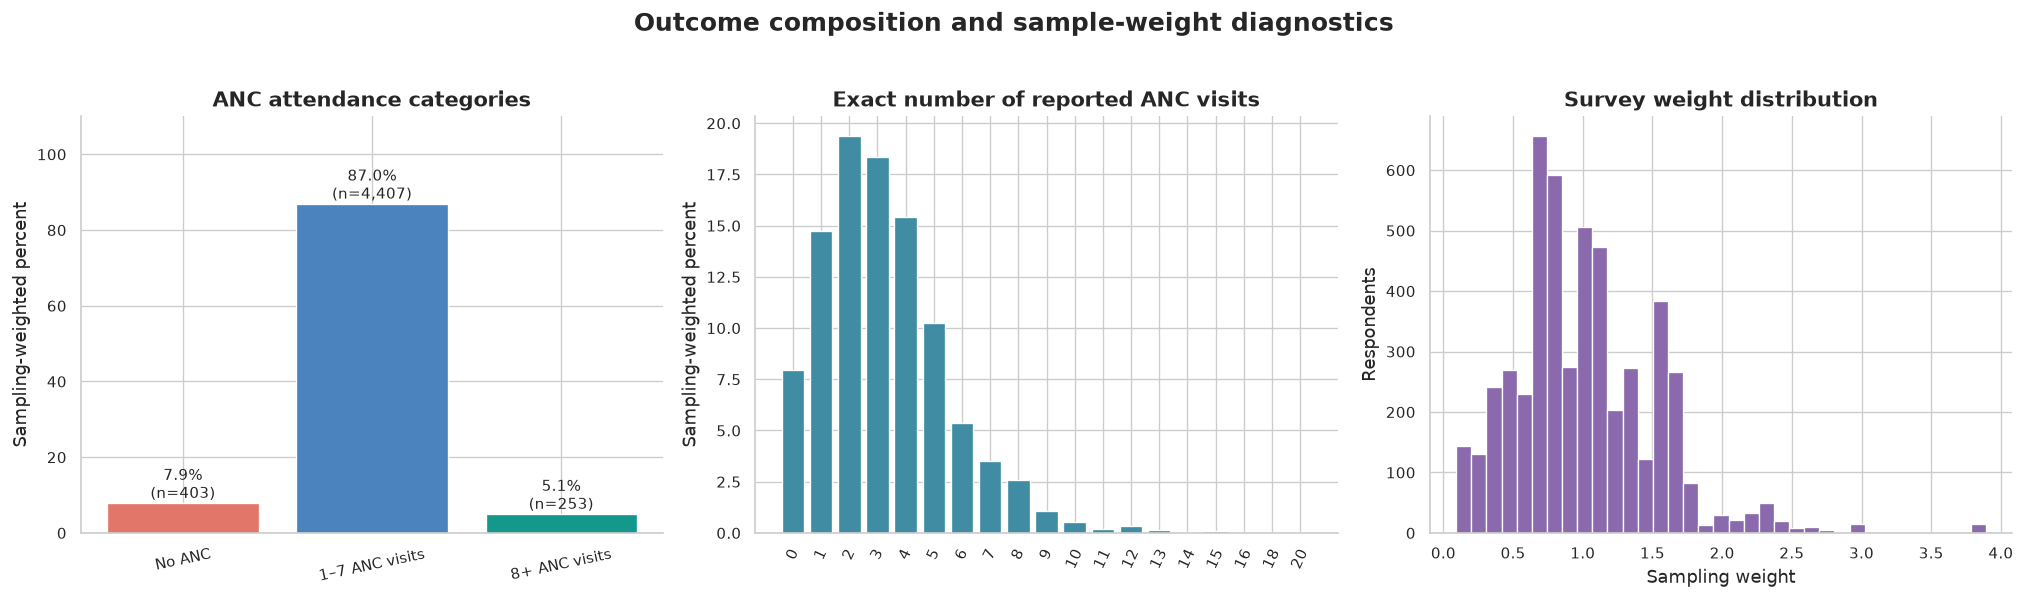

Outcome distribution:


,ANC_Class,Description,Unweighted_N,Unweighted_Pct,Weighted_Pct,CI_Low_Pct,CI_High_Pct,SE_Pct,Approx_Analytic_Sample_CI
0,0,No ANC,403,7.959708,7.943367,6.821535,9.065199,0.571318,True
1,1,1–7 ANC visits,4407,87.043255,87.002590,85.753572,88.251609,0.636090,True
2,2,8+ ANC visits,253,4.997037,5.054043,4.226561,5.881525,0.421414,True


In [4]:
# ----------------------------------------------------------------------------------------------
# Outcome prevalence and survey-weight quality diagnostics
# ----------------------------------------------------------------------------------------------
prev_rows = []
for k in range(3):
    e = weighted_estimate((y == k).astype(float))
    prev_rows.append({"ANC_Class": k, "Description": CLASS_TEXT[k],
                      "Unweighted_N": int((y == k).sum()), "Unweighted_Pct": 100 * (y == k).mean(),
                      "Weighted_Pct": 100 * e["Estimate"], "CI_Low_Pct": 100 * e["LCL"],
                      "CI_High_Pct": 100 * e["UCL"], "SE_Pct": 100 * e["SE"],
                      "Approx_Analytic_Sample_CI": True})
prevalence = pd.DataFrame(prev_rows)
save_csv(prevalence, "02_anc_prevalence")

counts = eda.ANC_VISITS.value_counts().sort_index()
visits = (eda.groupby("ANC_VISITS", observed=True)
          .agg(Unweighted_N=("ANC_CLASS", "size"), Weighted_N=("SURVEY_WEIGHT", "sum"))
          .reset_index())
visits["Weighted_Pct"] = 100 * visits["Weighted_N"] / w.sum()
save_csv(visits, "03_exact_anc_visits")

weight_quality = pd.DataFrame({
    "Metric": ["N", "PSUs", "Strata", "Weight_sum", "Weight_min", "Weight_median", "Weight_max",
               "Weight_CV", "Kish_effective_N", "Kish_N_over_N"],
    "Value": [n, NPSU, NSTRATA, w.sum(), w.min(), np.median(w), w.max(),
              w.std(ddof=0)/w.mean(), w.sum()**2 / np.sum(w*w),
              (w.sum()**2 / np.sum(w*w)) / n]
})
save_csv(weight_quality, "04_weight_diagnostics", "01_qc")
psu_counts = eda.groupby(["STRATUM", "PSU"], observed=True).size().reset_index(name="Analytic_N")
psu_counts["Singleton_Analytic_PSU"] = psu_counts.Analytic_N.eq(1)
save_csv(psu_counts, "05_psu_size_audit", "01_qc")

fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
axs[0].bar(prevalence.Description, prevalence.Weighted_Pct, color=PALETTE)
for i, row in prevalence.iterrows():
    axs[0].text(i, row.Weighted_Pct + 1.3, f"{row.Weighted_Pct:.1f}%\n(n={row.Unweighted_N:,})",
                ha="center", fontsize=9)
axs[0].set_ylim(0, 110); axs[0].set_ylabel("Sampling-weighted percent")
axs[0].set_title("ANC attendance categories")
axs[0].tick_params(axis="x", rotation=12)
axs[1].bar(visits.ANC_VISITS.astype(str), visits.Weighted_Pct, color="#3F8CA3")
axs[1].set_title("Exact number of reported ANC visits")
axs[1].set_ylabel("Sampling-weighted percent")
axs[1].tick_params(axis="x", rotation=65)
axs[2].hist(w, bins=35, color="#8A69AD", edgecolor="white")
axs[2].set_title("Survey weight distribution")
axs[2].set_xlabel("Sampling weight"); axs[2].set_ylabel("Respondents")
fig.suptitle("Outcome composition and sample-weight diagnostics", fontsize=15, fontweight="bold", y=1.03)
fig.tight_layout(); save_plot(fig, "01_outcome_distribution_and_weights")
print("Outcome distribution:"); display(prevalence)

## 05 | Numerical predictors: distribution, normality, Q–Q, ECDF, and class differences

Normality tests describe marginal distributions; they do not determine whether a predictor may enter logistic regression or tree models. Prior births and household size are integer-valued counts.

C:\Users\M R Computer\AppData\Local\Temp\ipykernel_7812\3509048459.py:34: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  ad = stats.anderson(x, dist="norm")


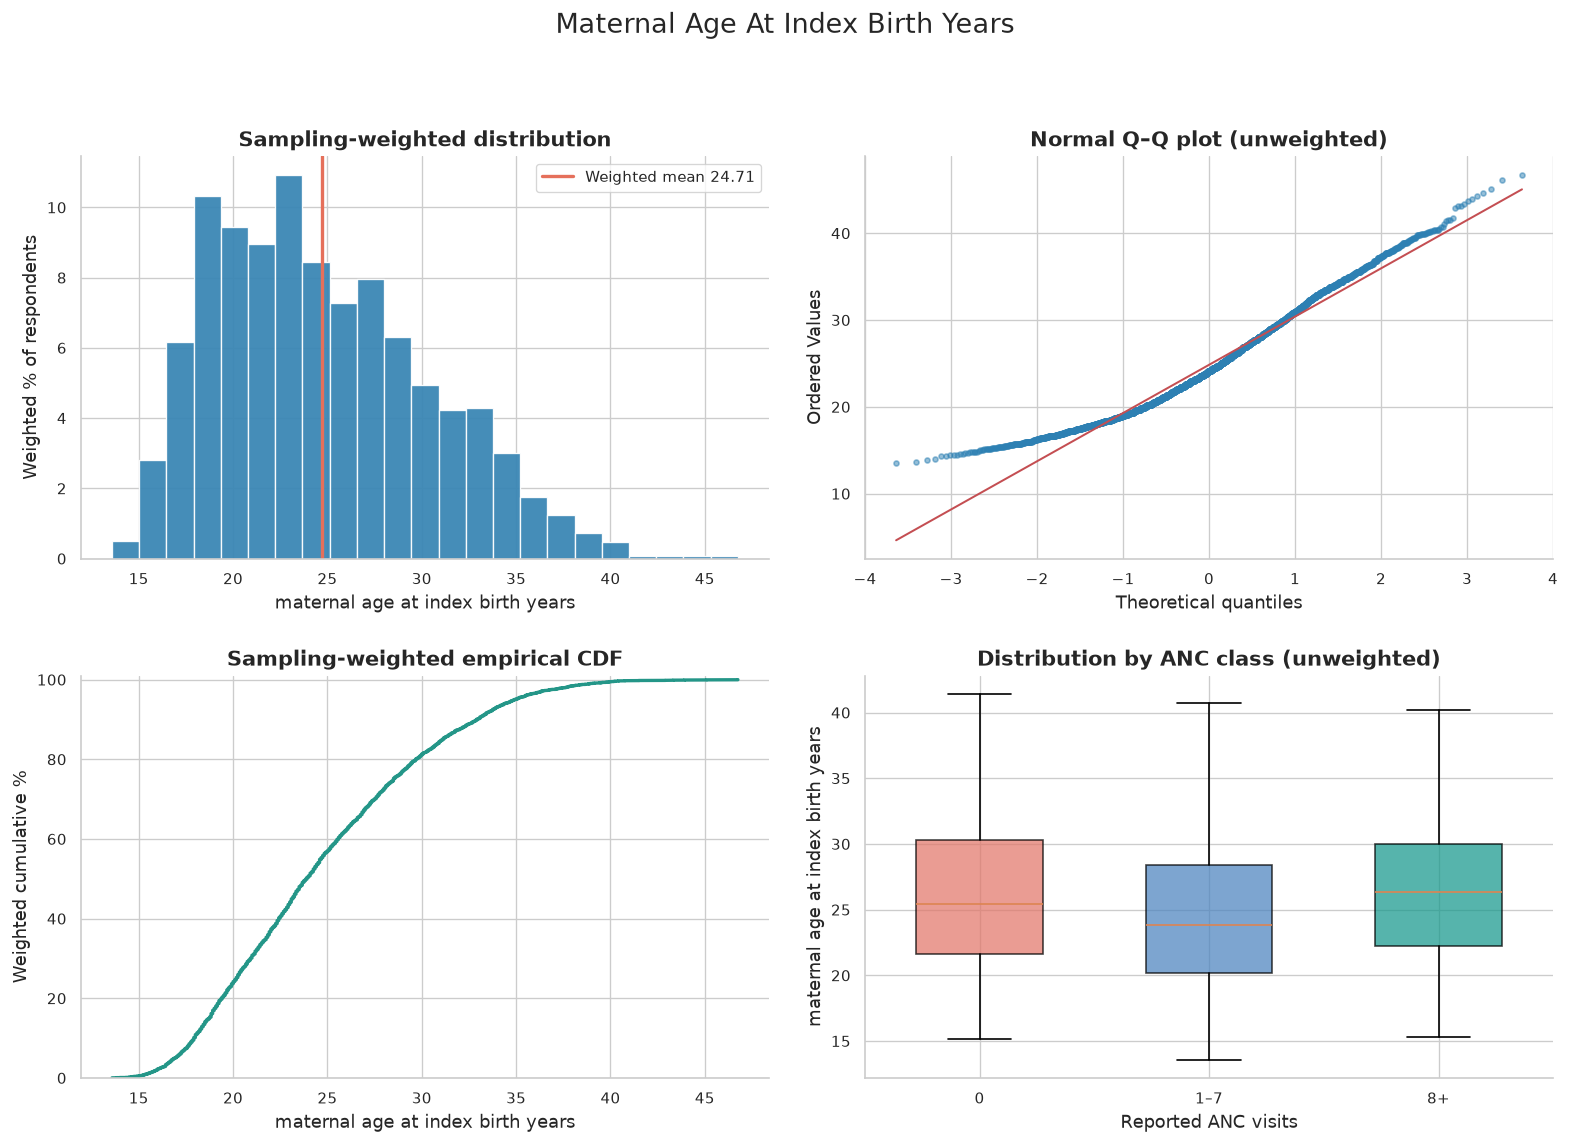

C:\Users\M R Computer\AppData\Local\Temp\ipykernel_7812\3509048459.py:34: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  ad = stats.anderson(x, dist="norm")


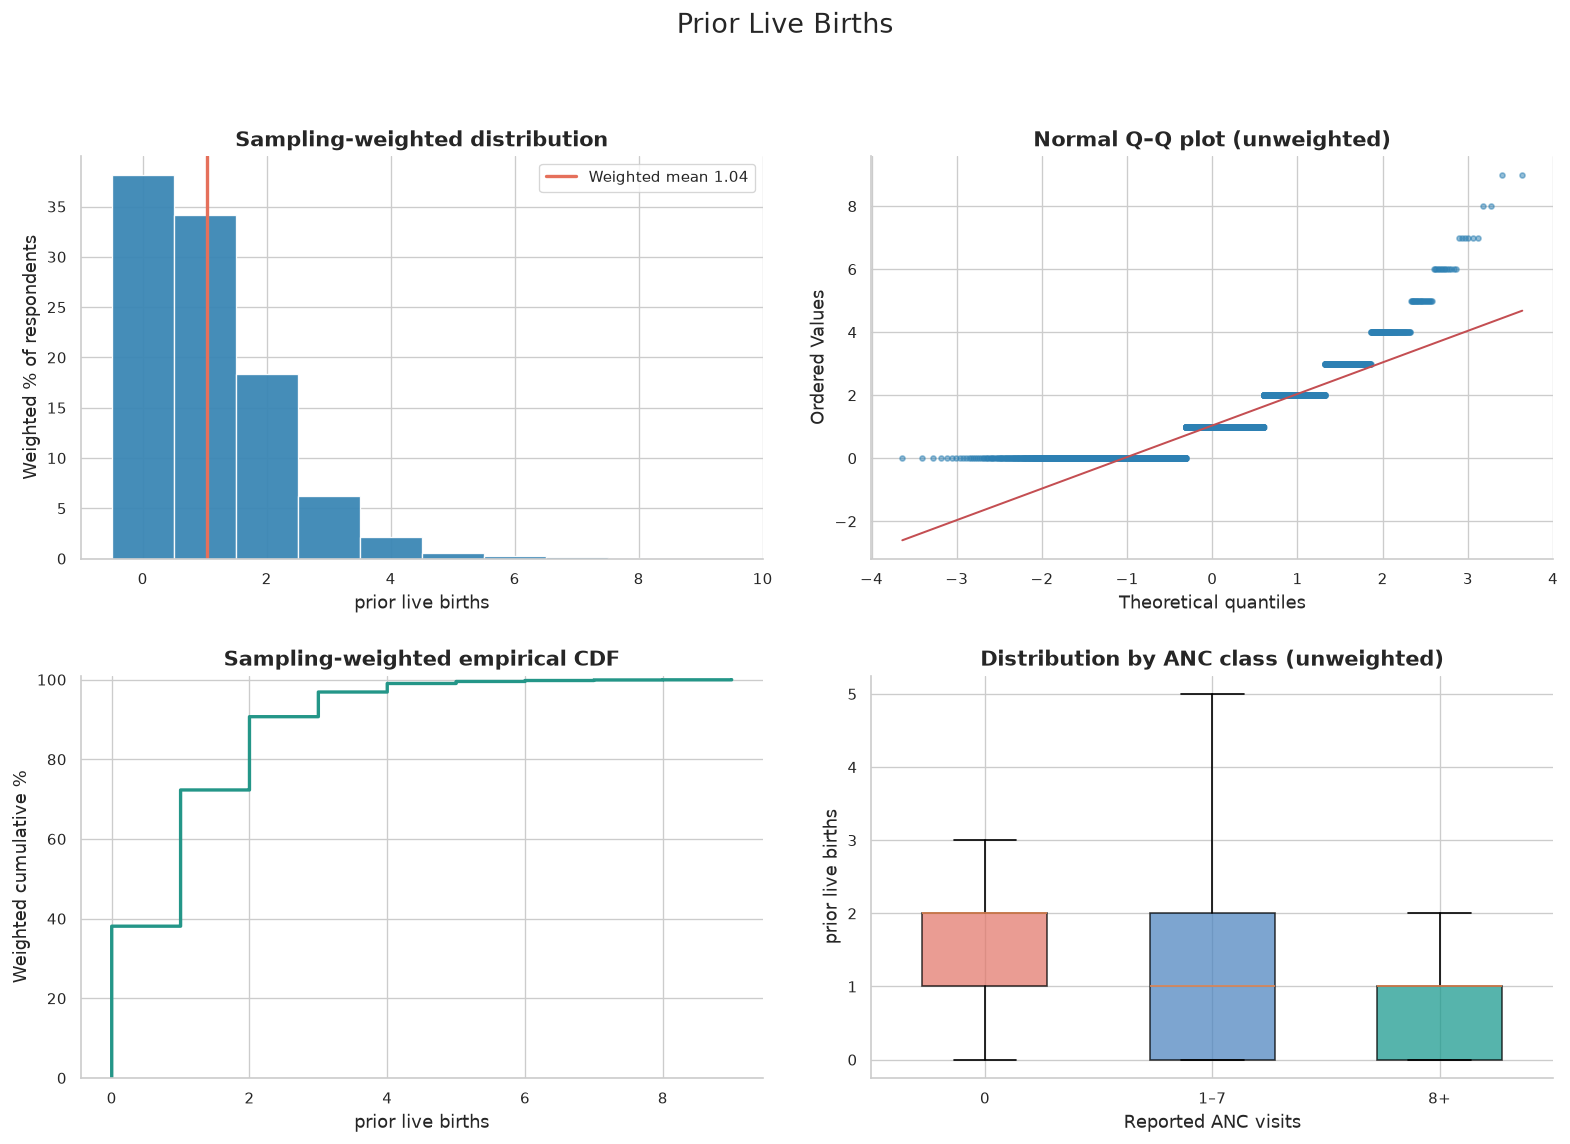

C:\Users\M R Computer\AppData\Local\Temp\ipykernel_7812\3509048459.py:34: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  ad = stats.anderson(x, dist="norm")


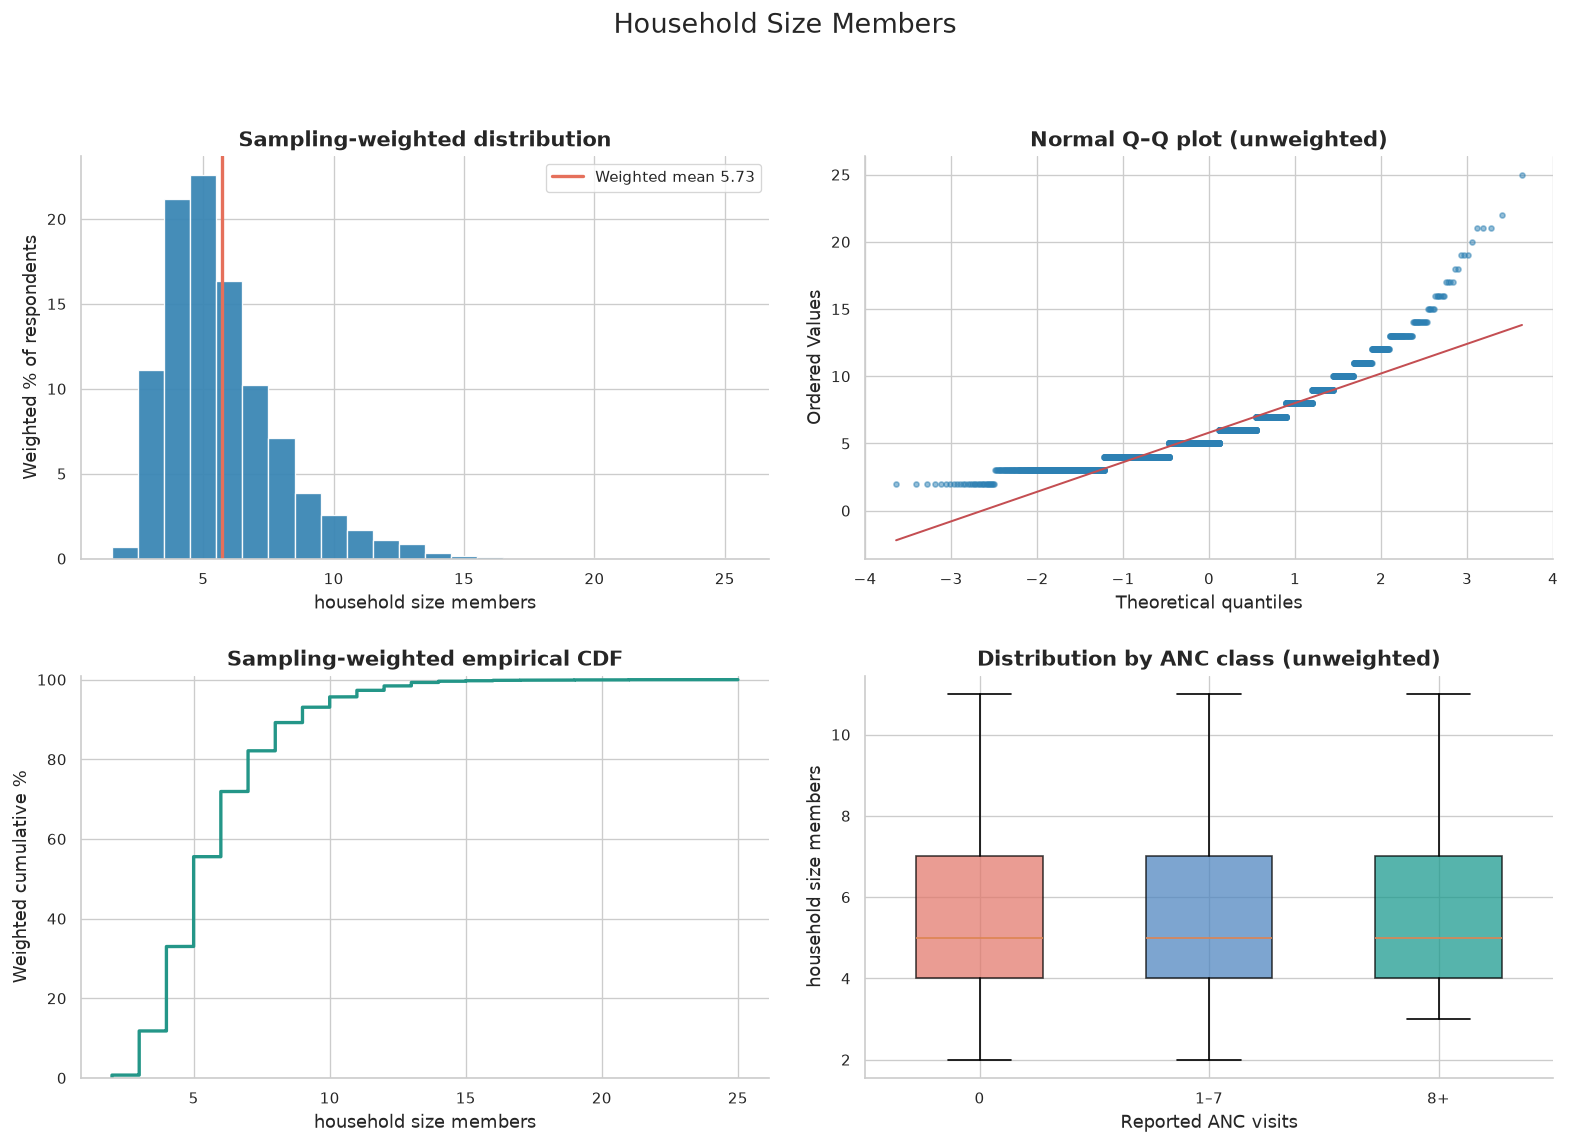

Numeric distribution and normality results:


,Predictor,N,Minimum,Maximum,Mean,SD,Median,Weighted_Mean,Weighted_Mean_LCL,Weighted_Mean_UCL,Weighted_P01,Weighted_P25,Weighted_Median,Weighted_P75,Weighted_P99,Skewness,Excess_Kurtosis,Zero_Count,IQR_Flag_N
0,maternal_age_at_index_birth_years,5063,13.583,46.75,24.838,5.635,24.083,24.709,24.524,24.893,15.464,20.167,23.917,28.5,38.917,0.545,-0.263,0,16
1,prior_live_births,5063,0.000,9.00,1.039,1.111,1.000,1.039,0.998,1.079,0.000,0.000,1.000,2.0,4.000,1.458,3.627,1909,24
2,household_size_members,5063,2.000,25.00,5.802,2.356,5.000,5.734,5.644,5.824,3.000,4.000,5.000,7.0,13.000,1.616,4.675,0,148


,Predictor,Shapiro_N,Shapiro_W,Shapiro_p,DAgostino_K2,DAgostino_p,Anderson_A2,Anderson_5pct_Critical,Interpretation
0,maternal_age_at_index_birth_years,3000,0.9691,0.0,240.0792,0.0,39.6419,0.752,Diagnostic only; large samples and discrete va...
1,prior_live_births,3000,0.8125,0.0,1450.9626,0.0,302.6729,0.752,Diagnostic only; large samples and discrete va...
2,household_size_members,3000,0.8874,0.0,1695.5049,0.0,164.9704,0.752,Diagnostic only; large samples and discrete va...


In [5]:
# ----------------------------------------------------------------------------------------------
# Descriptive moments, normality statistics, outlier flags, Q-Q and distribution figures
# ----------------------------------------------------------------------------------------------
rng = np.random.default_rng(2026)
numeric_rows = []
normality_rows = []
num_by_class = []
flag_rows = []

for feature in NUMERIC:
    x = eda[feature].to_numpy(dtype=float)
    weighted_mean = weighted_estimate(x, interval=False)
    q01, q25, q50, q75, q99 = weighted_quantile(x, [.01, .25, .5, .75, .99])
    lo, hi = np.percentile(x, [25, 75]); spread = hi - lo
    lower, upper = lo - 1.5 * spread, hi + 1.5 * spread
    iqr_flags = (x < lower) | (x > upper)
    flag_rows.append({"Predictor": feature, "Lower_Fence": lower, "Upper_Fence": upper,
                      "N_Flagged": int(iqr_flags.sum()), "Flagged_Pct": 100 * iqr_flags.mean(),
                      "Action": "Review only; observations retained"})
    numeric_rows.append({
        "Predictor": feature, "N": len(x), "Minimum": x.min(), "Maximum": x.max(),
        "Mean": x.mean(), "SD": x.std(ddof=1), "Median": np.median(x),
        "Weighted_Mean": weighted_mean["Estimate"], "Weighted_Mean_LCL": weighted_mean["LCL"],
        "Weighted_Mean_UCL": weighted_mean["UCL"], "Weighted_P01": q01, "Weighted_P25": q25,
        "Weighted_Median": q50, "Weighted_P75": q75, "Weighted_P99": q99,
        "Skewness": stats.skew(x), "Excess_Kurtosis": stats.kurtosis(x),
        "Zero_Count": int(np.isclose(x, 0).sum()), "IQR_Flag_N": int(iqr_flags.sum())
    })

    # Shapiro-Wilk uses a fixed reproducible subsample to avoid N > 5,000 warnings.
    tested = x[rng.choice(len(x), size=min(3000, len(x)), replace=False)]
    sw = stats.shapiro(tested)
    dag = stats.normaltest(x)
    ad = stats.anderson(x, dist="norm")
    normality_rows.append({"Predictor": feature, "Shapiro_N": len(tested),
                           "Shapiro_W": sw.statistic, "Shapiro_p": sw.pvalue,
                           "DAgostino_K2": dag.statistic, "DAgostino_p": dag.pvalue,
                           "Anderson_A2": ad.statistic,
                           "Anderson_5pct_Critical": ad.critical_values[list(ad.significance_level).index(5.0)],
                           "Interpretation": "Diagnostic only; large samples and discrete variables may reject normality"})

    for k in range(3):
        e = weighted_estimate(x, y == k, interval=False)
        nrows = int((y == k).sum())
        qk = weighted_quantile(x[y == k], [.25, .5, .75], weights=w[y == k])
        num_by_class.append({"Predictor": feature, "ANC_Class": k, "ANC_Description": CLASS_TEXT[k],
                             "N": nrows, "Unweighted_Mean": x[y == k].mean(),
                             "Weighted_Mean": e["Estimate"], "Weighted_Mean_LCL": e["LCL"],
                             "Weighted_Mean_UCL": e["UCL"], "Weighted_Median": qk[1],
                             "Weighted_Q1": qk[0], "Weighted_Q3": qk[2]})

    fig, ax = plt.subplots(2, 2, figsize=(13.5, 9.5))
    bins = min(45, max(12, int(np.sqrt(x.max() - x.min() + 1) * 4)))
    if feature != "maternal_age_at_index_birth_years":
        edges = np.arange(np.floor(x.min())-.5, np.ceil(x.max())+1.5, 1)
        if len(edges) > 80: edges = bins
    else:
        edges = bins
    ax[0,0].hist(x, bins=edges, weights=100 * w / w.sum(),
                 color="#3986B4", edgecolor="white", alpha=.94)
    ax[0,0].axvline(weighted_mean["Estimate"], color="#E5705B", linewidth=2,
                    label=f"Weighted mean {weighted_mean['Estimate']:.2f}")
    ax[0,0].set(xlabel=feature.replace("_", " "), ylabel="Weighted % of respondents",
                 title="Sampling-weighted distribution")
    ax[0,0].legend(loc="best")
    stats.probplot(x, dist="norm", plot=ax[0,1])
    ax[0,1].set_title("Normal Q–Q plot (unweighted)")
    ax[0,1].get_lines()[0].set(color="#2D80B3", markersize=3, alpha=.5)
    xi = np.argsort(x)
    ax[1,0].step(x[xi], 100 * np.cumsum(w[xi]) / w.sum(),
                 where="post", color="#249688", linewidth=2)
    ax[1,0].set(xlabel=feature.replace("_", " "), ylabel="Weighted cumulative %",
                 title="Sampling-weighted empirical CDF")
    ax[1,0].set_ylim(0, 101)
    bp = ax[1,1].boxplot([x[y == k] for k in range(3)],
                         tick_labels=["0", "1–7", "8+"], patch_artist=True,
                         showfliers=False, widths=.55)
    for patch, col in zip(bp["boxes"], PALETTE):
        patch.set_facecolor(col); patch.set_alpha(.72)
    ax[1,1].set(xlabel="Reported ANC visits", ylabel=feature.replace("_", " "),
                title="Distribution by ANC class (unweighted)")
    fig.suptitle(feature.replace("_", " ").title(), fontsize=16, y=1.015)
    fig.tight_layout(pad=2.2)
    save_plot(fig, f"02_NUM_{feature}")

numeric_stats = pd.DataFrame(numeric_rows)
normality = pd.DataFrame(normality_rows)
num_class = pd.DataFrame(num_by_class)
outlier_flags = pd.DataFrame(flag_rows)
save_csv(numeric_stats, "06_numeric_summary")
save_csv(normality, "07_normality_diagnostics")
save_csv(num_class, "08_numeric_by_anc_class")
save_csv(outlier_flags, "09_numeric_iqr_flags", "01_qc")
print("Numeric distribution and normality results:")
display(numeric_stats.round(3)); display(normality.round(4))

## 06 | Categorical predictor distributions, ANC subgroup prevalences, and sparse cells

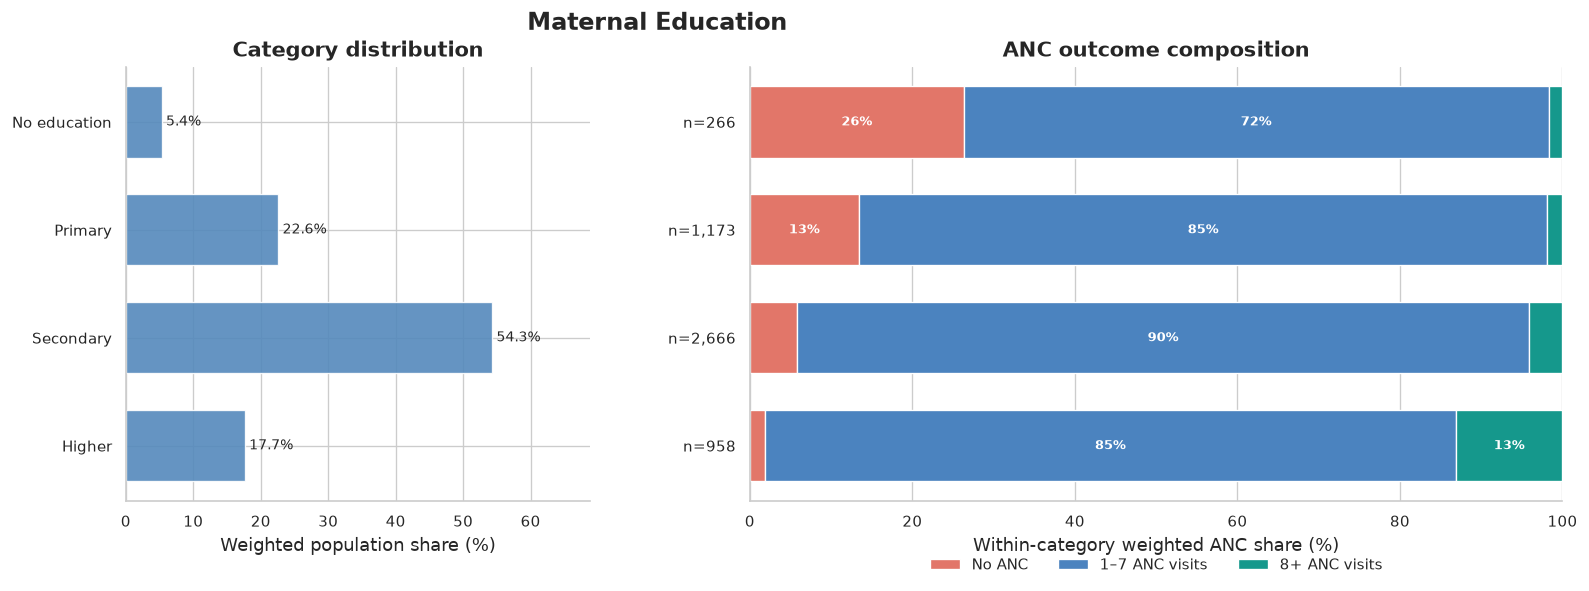

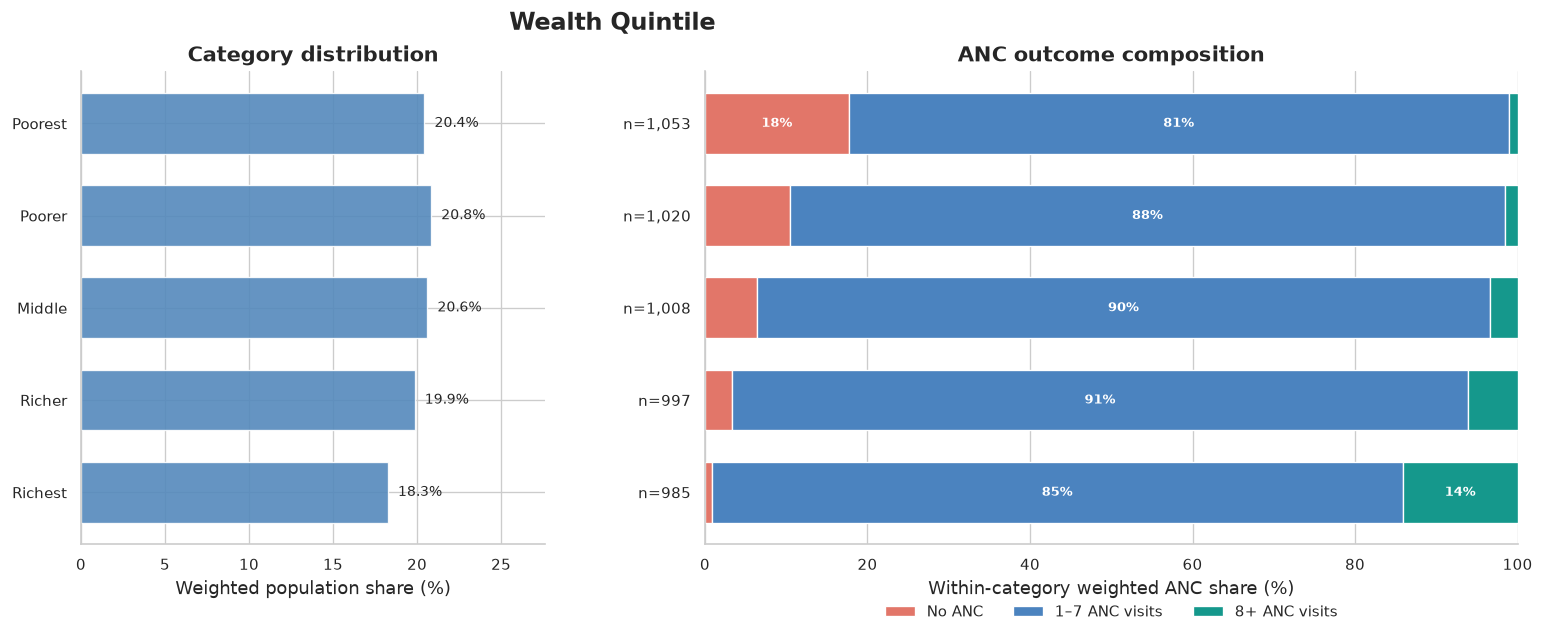

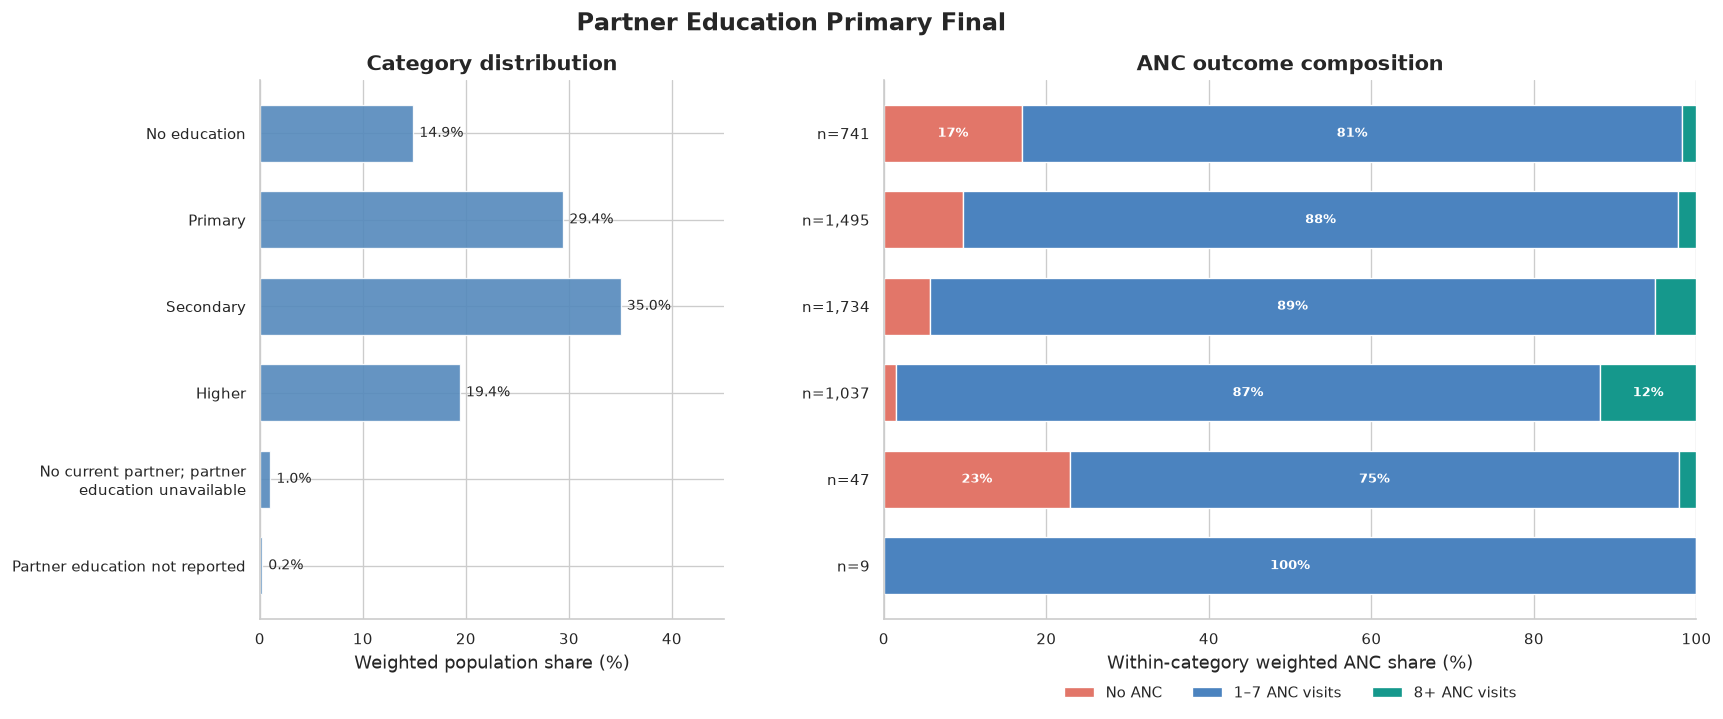

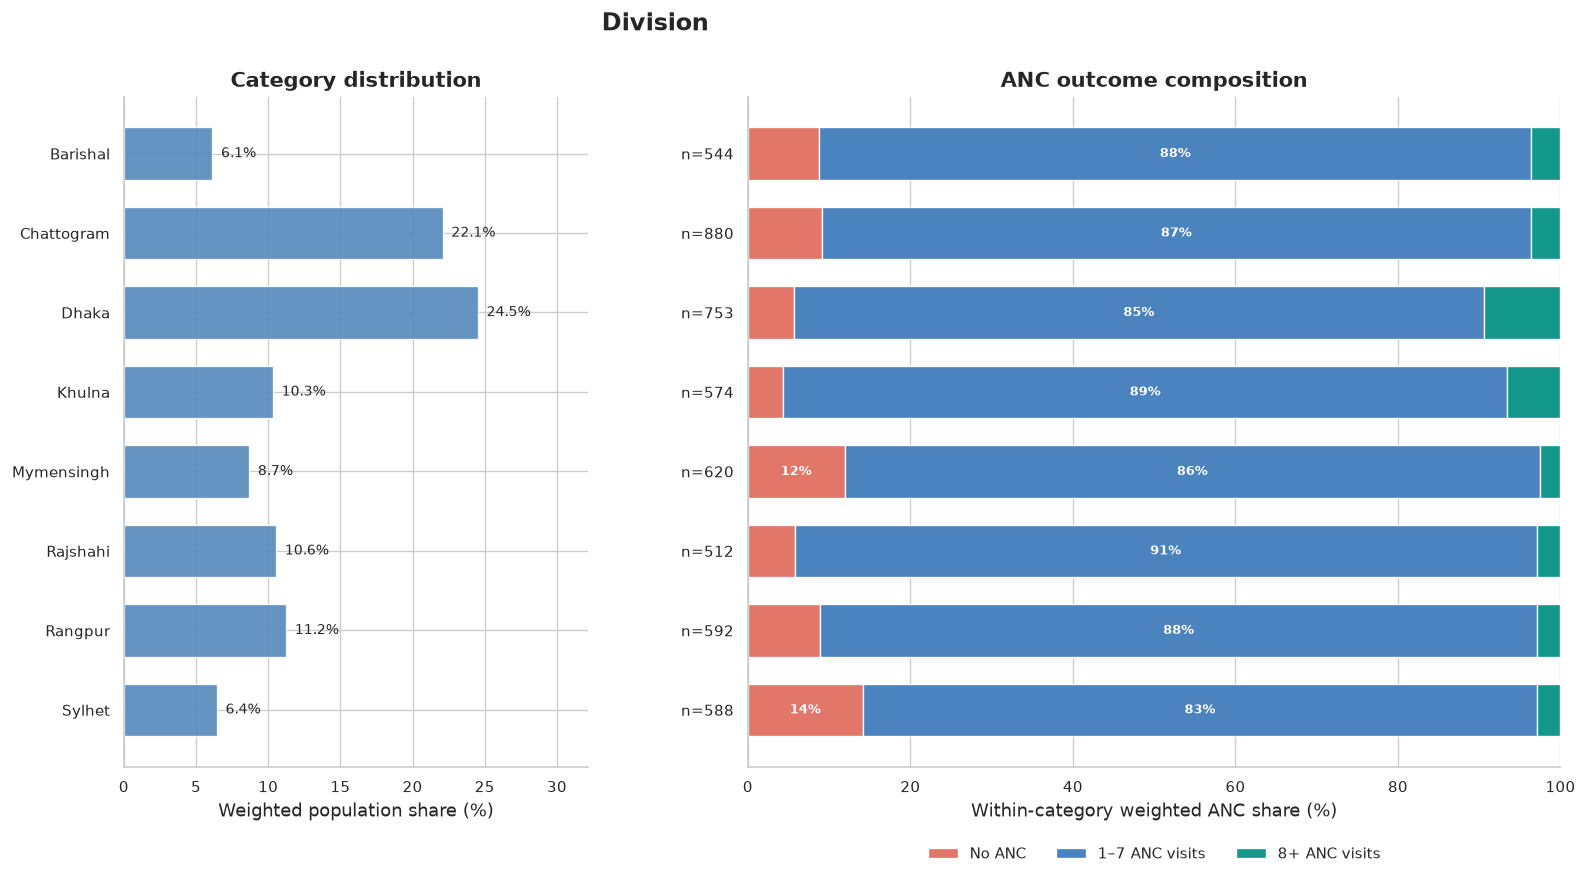

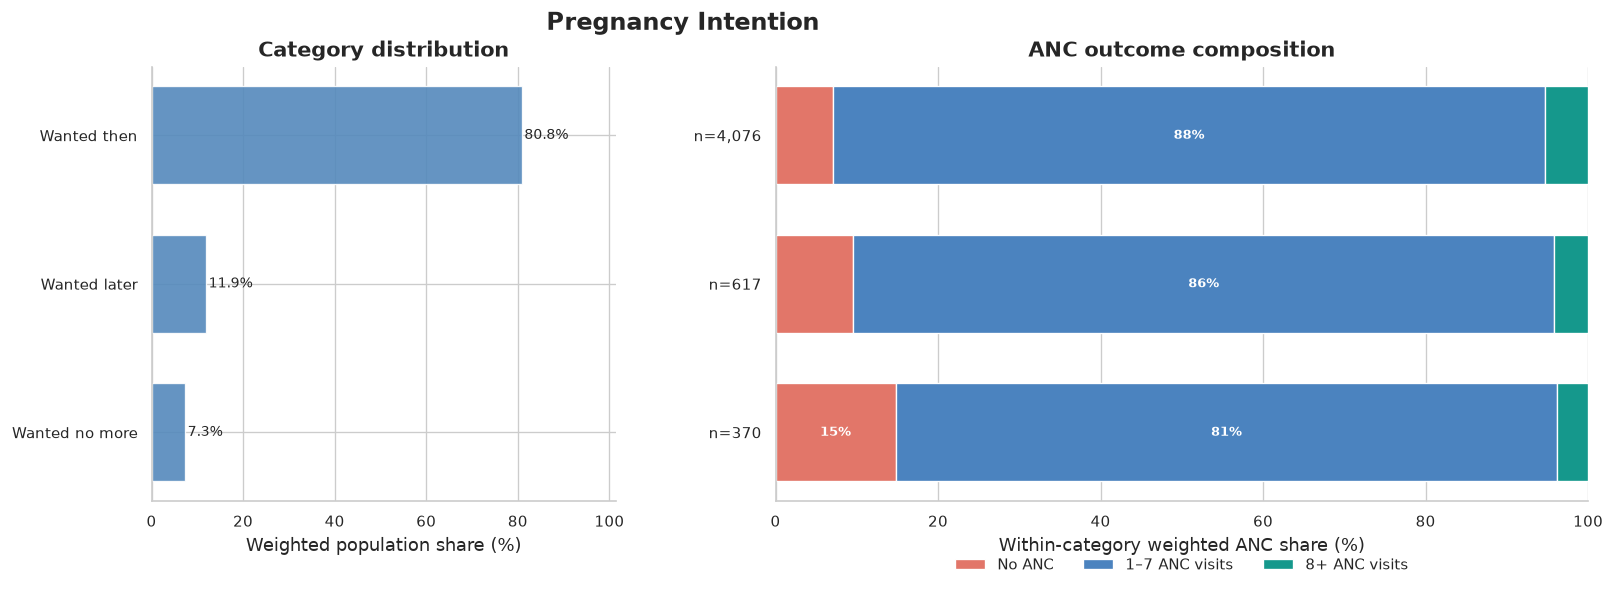

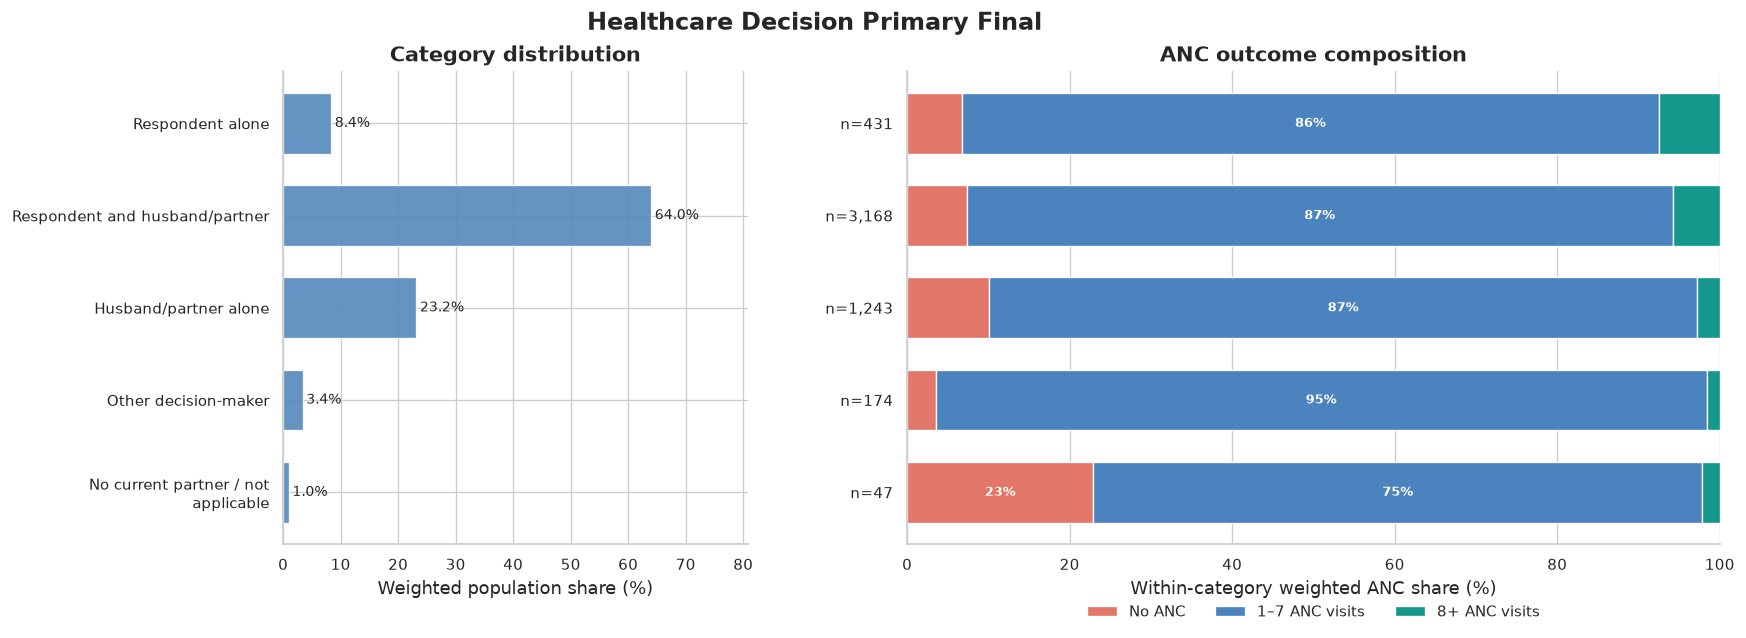

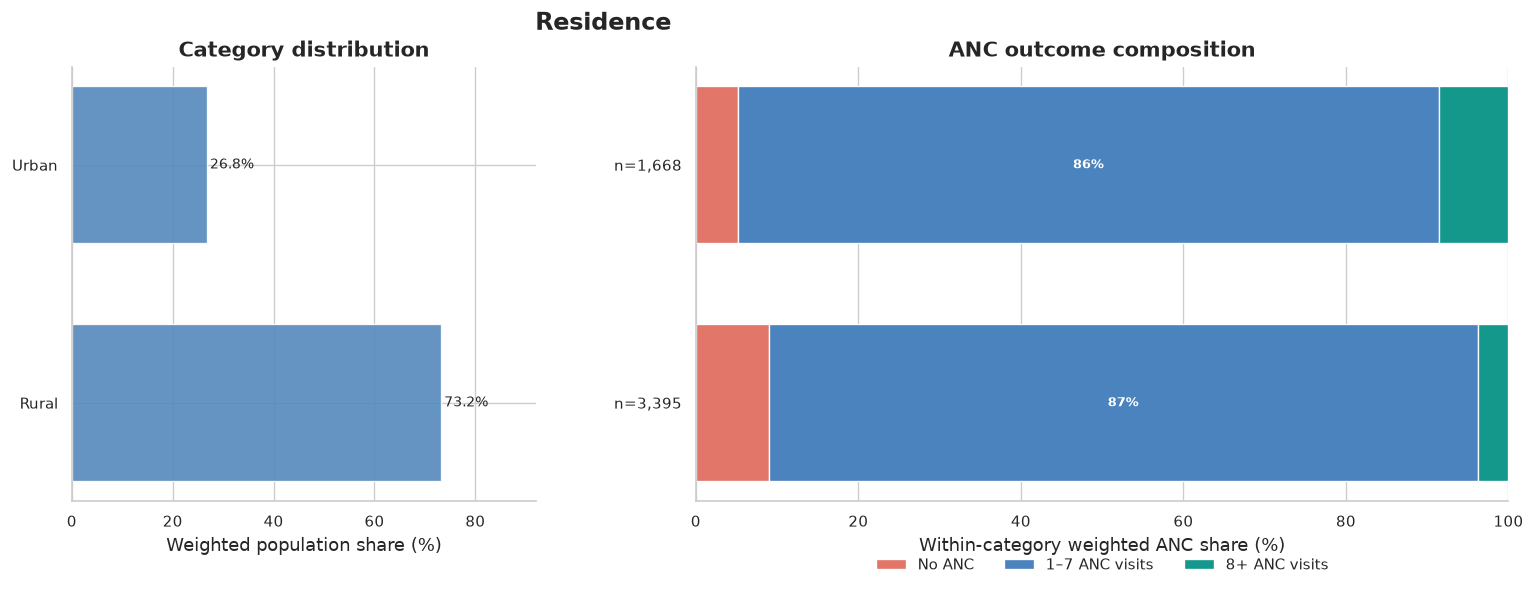

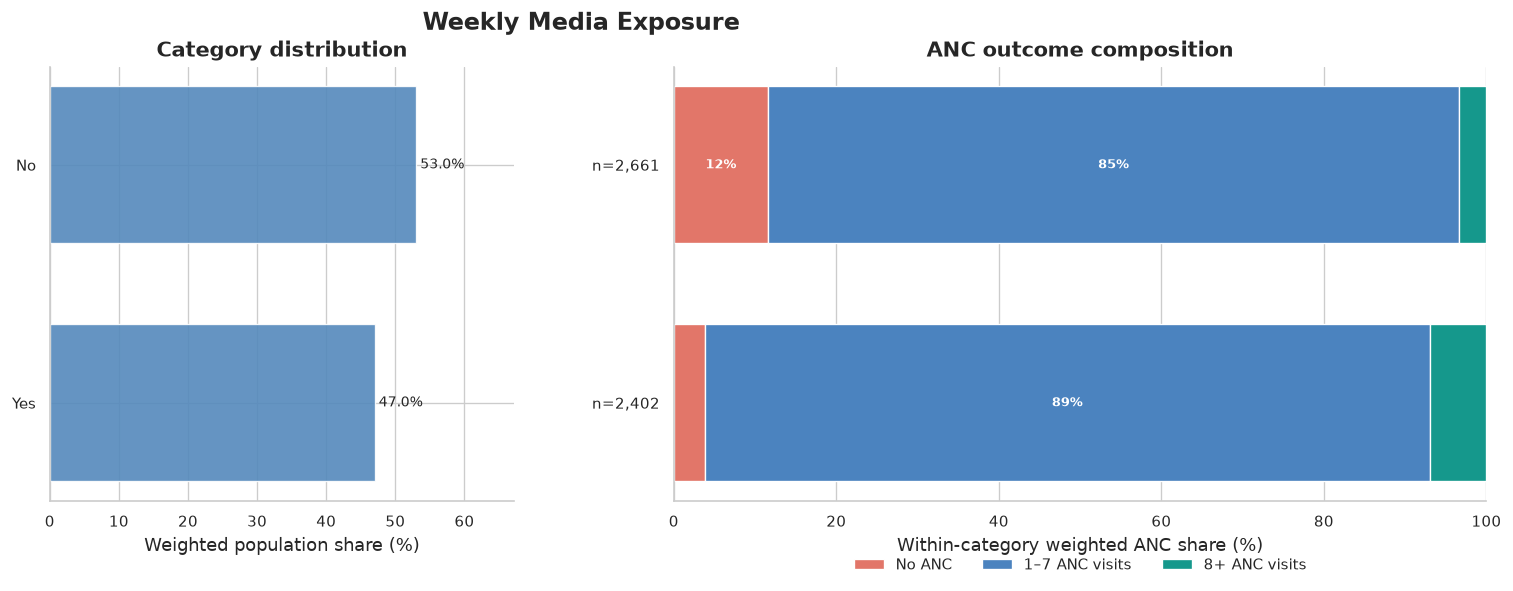

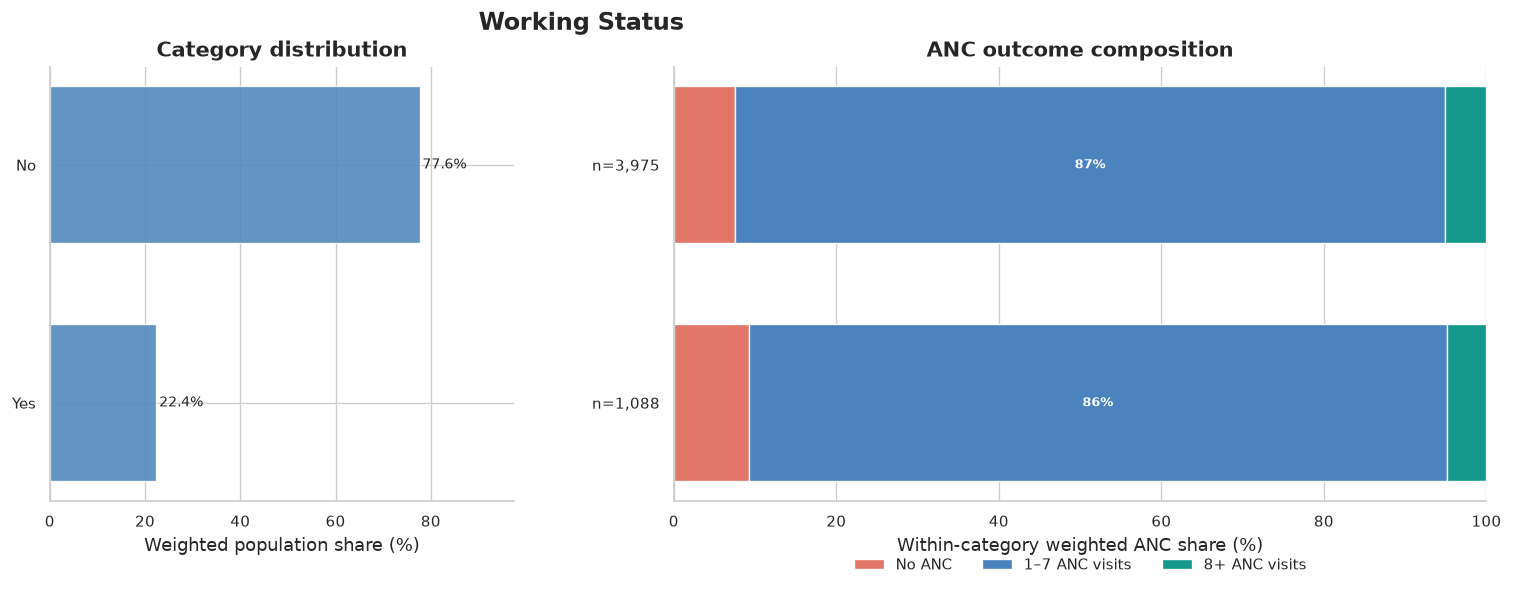

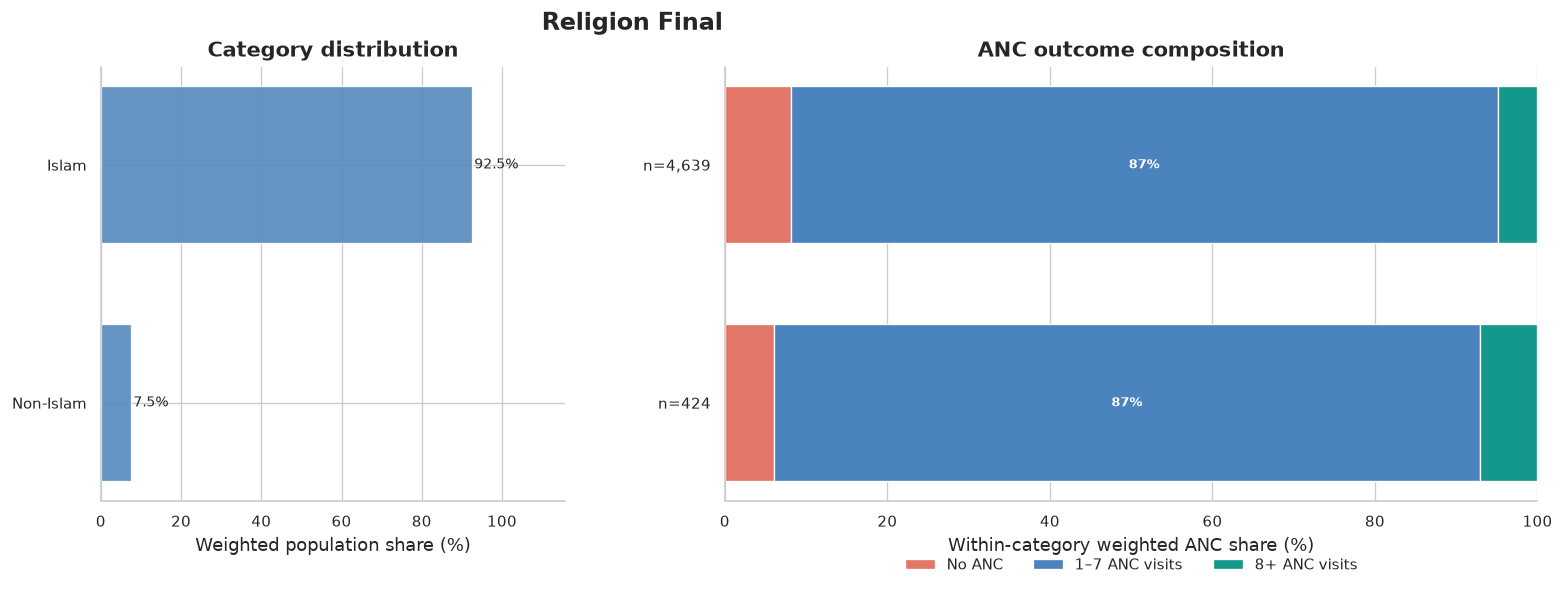

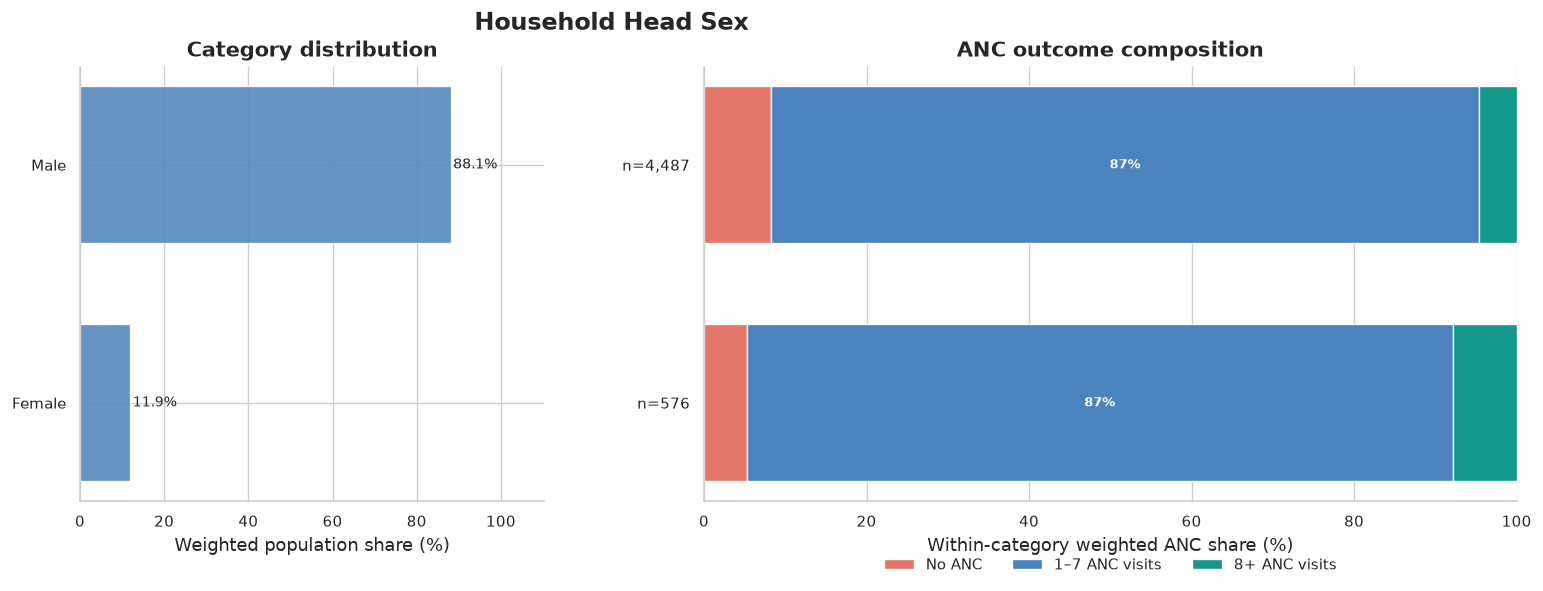

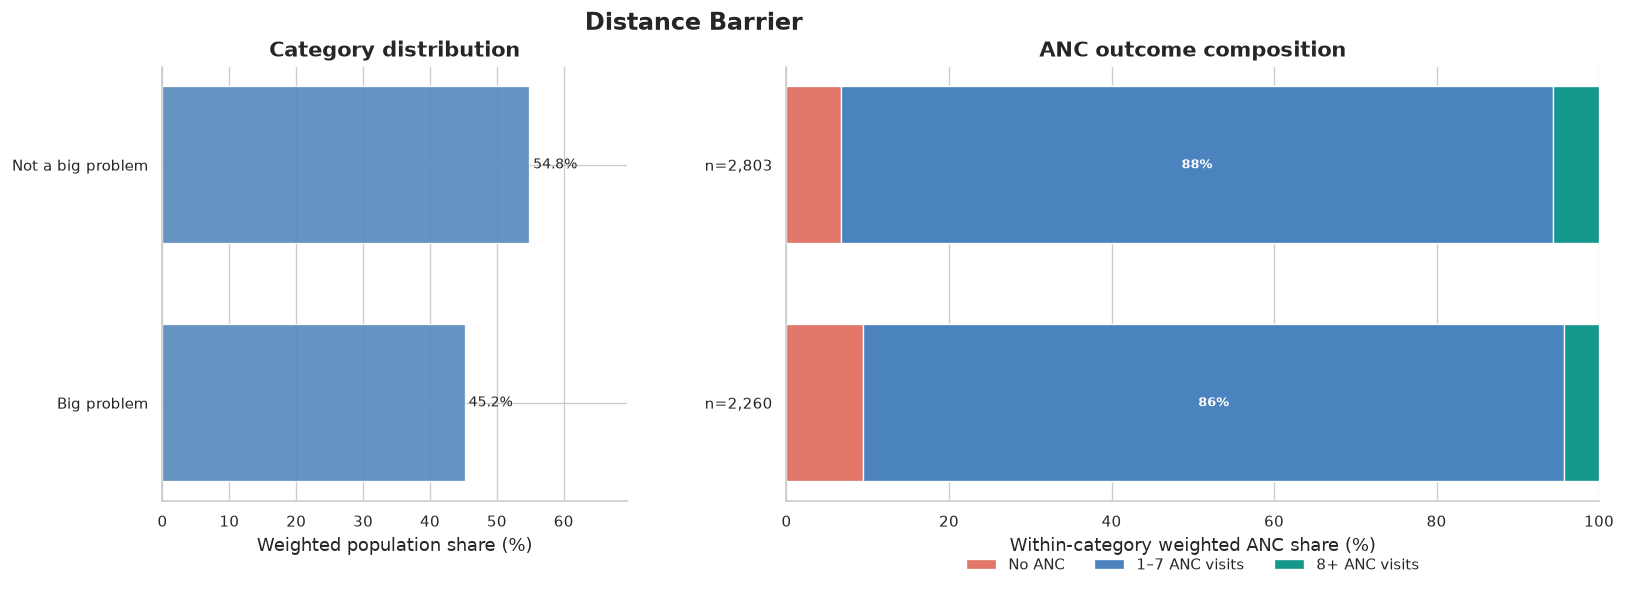

Categorical predictors: 12; distinct category labels across predictors: 43
Categorical outcome cells with n < 5: 6


,Predictor,Category,ANC_Class,Cell_N,Group_N,Flag_Cell_Below_5,Flag_Group_Below_30
2,maternal_education,No education,2,4,266,True,False
41,partner_education_primary_final,No current partner; partner education unavailable,2,2,47,True,False
42,partner_education_primary_final,Partner education not reported,0,0,9,True,True
44,partner_education_primary_final,Partner education not reported,2,0,9,True,True
89,healthcare_decision_primary_final,Other decision-maker,2,3,174,True,False
92,healthcare_decision_primary_final,No current partner / not applicable,2,2,47,True,False


In [6]:
# ----------------------------------------------------------------------------------------------
# Categorical predictor-level profiles and 100%-stacked ANC composition charts
# ----------------------------------------------------------------------------------------------
cat_rows = []
sparse_rows = []

for feature in CATEGORICAL:
    values = eda[feature].astype(str).to_numpy()
    levels = LEVEL_ORDERS[feature]
    profile = []
    for level in levels:
        mask = values == level
        ncat = int(mask.sum())
        category_weight_pct = 100 * w[mask].sum() / w.sum()
        rates = []
        for k in range(3):
            this_cell = int((mask & (y == k)).sum())
            e = weighted_estimate((y == k).astype(float), mask)
            rate = 100 * e["Estimate"]
            rates.append(rate)
            cat_rows.append({"Predictor": feature, "Category": level,
                             "Unweighted_N": ncat, "Weighted_Population_Pct": category_weight_pct,
                             "ANC_Class": k, "ANC_Description": CLASS_TEXT[k],
                             "ANC_Class_Cell_N": this_cell, "ANC_Weighted_Pct": rate,
                             "ANC_CI_Lower_Pct": 100 * e["LCL"], "ANC_CI_Upper_Pct": 100 * e["UCL"],
                             "Kish_N": e["Kish_N"], "Domain_PSU_N": e["PSU_N"]})
            sparse_rows.append({"Predictor": feature, "Category": level, "ANC_Class": k,
                                "Cell_N": this_cell, "Group_N": ncat,
                                "Flag_Cell_Below_5": this_cell < 5,
                                "Flag_Group_Below_30": ncat < 30})
        profile.append((level, ncat, category_weight_pct, rates))

    labels = [fill(t[0], width=30) for t in profile]
    locations = np.arange(len(profile))
    fig, axes = plt.subplots(1, 2, figsize=(16.4, max(5.1, .77*len(profile)+1.7)),
                             gridspec_kw={"width_ratios": [1, 1.75]})
    sizes = [t[2] for t in profile]
    axes[0].barh(locations, sizes, color="#5489BC", alpha=.9, height=.66)
    for j, v in enumerate(sizes):
        axes[0].text(v + .6, j, f"{v:.1f}%", va="center", fontsize=8.4)
    axes[0].set_xlim(0, max(sizes) * 1.23 + 2)
    axes[0].set_yticks(locations, labels)
    axes[0].invert_yaxis()
    axes[0].set_xlabel("Weighted population share (%)")
    axes[0].set_title("Category distribution")

    left = np.zeros(len(profile))
    for k in range(3):
        this = np.array([t[3][k] for t in profile])
        axes[1].barh(locations, this, left=left, color=COLORS[k], height=.66,
                     label=CLASS_TEXT[k])
        for j, val in enumerate(this):
            if val >= 11:
                axes[1].text(left[j] + val/2, j, f"{val:.0f}%",
                             ha="center", va="center", color="white", fontsize=8, fontweight="bold")
        left += this
    axes[1].set_yticks(locations, [f"n={t[1]:,}" for t in profile]); axes[1].invert_yaxis()
    axes[1].set_xlim(0, 100); axes[1].set_xlabel("Within-category weighted ANC share (%)")
    axes[1].set_title("ANC outcome composition")
    axes[1].legend(loc="upper center", bbox_to_anchor=(.5,-.10), ncol=3, frameon=False, fontsize=9)
    fig.suptitle(feature.replace("_", " ").title(), fontsize=14.5, fontweight="bold", y=.99)
    fig.subplots_adjust(left=.23, right=.96, top=.9, bottom=.19, wspace=.25)
    save_plot(fig, f"03_CAT_{feature}")

cat_table = pd.DataFrame(cat_rows)
sparse = pd.DataFrame(sparse_rows)
save_csv(cat_table, "10_all_categorical_anc_profiles")
save_csv(sparse, "11_sparse_categorical_anc_cells", "01_qc")
print(f"Categorical predictors: {len(CATEGORICAL)}; distinct category labels across predictors: {sum(map(len, LEVEL_ORDERS.values()))}")
print(f"Categorical outcome cells with n < 5: {int(sparse.Flag_Cell_Below_5.sum())}")
display(sparse[sparse.Flag_Cell_Below_5].head(18))

## 07 | Pairwise association and dependence matrices

Weighted correlations and Cramér's V are descriptive measures. Large absolute associations indicate potential redundancy but are **not** grounds for changing the frozen predictors.

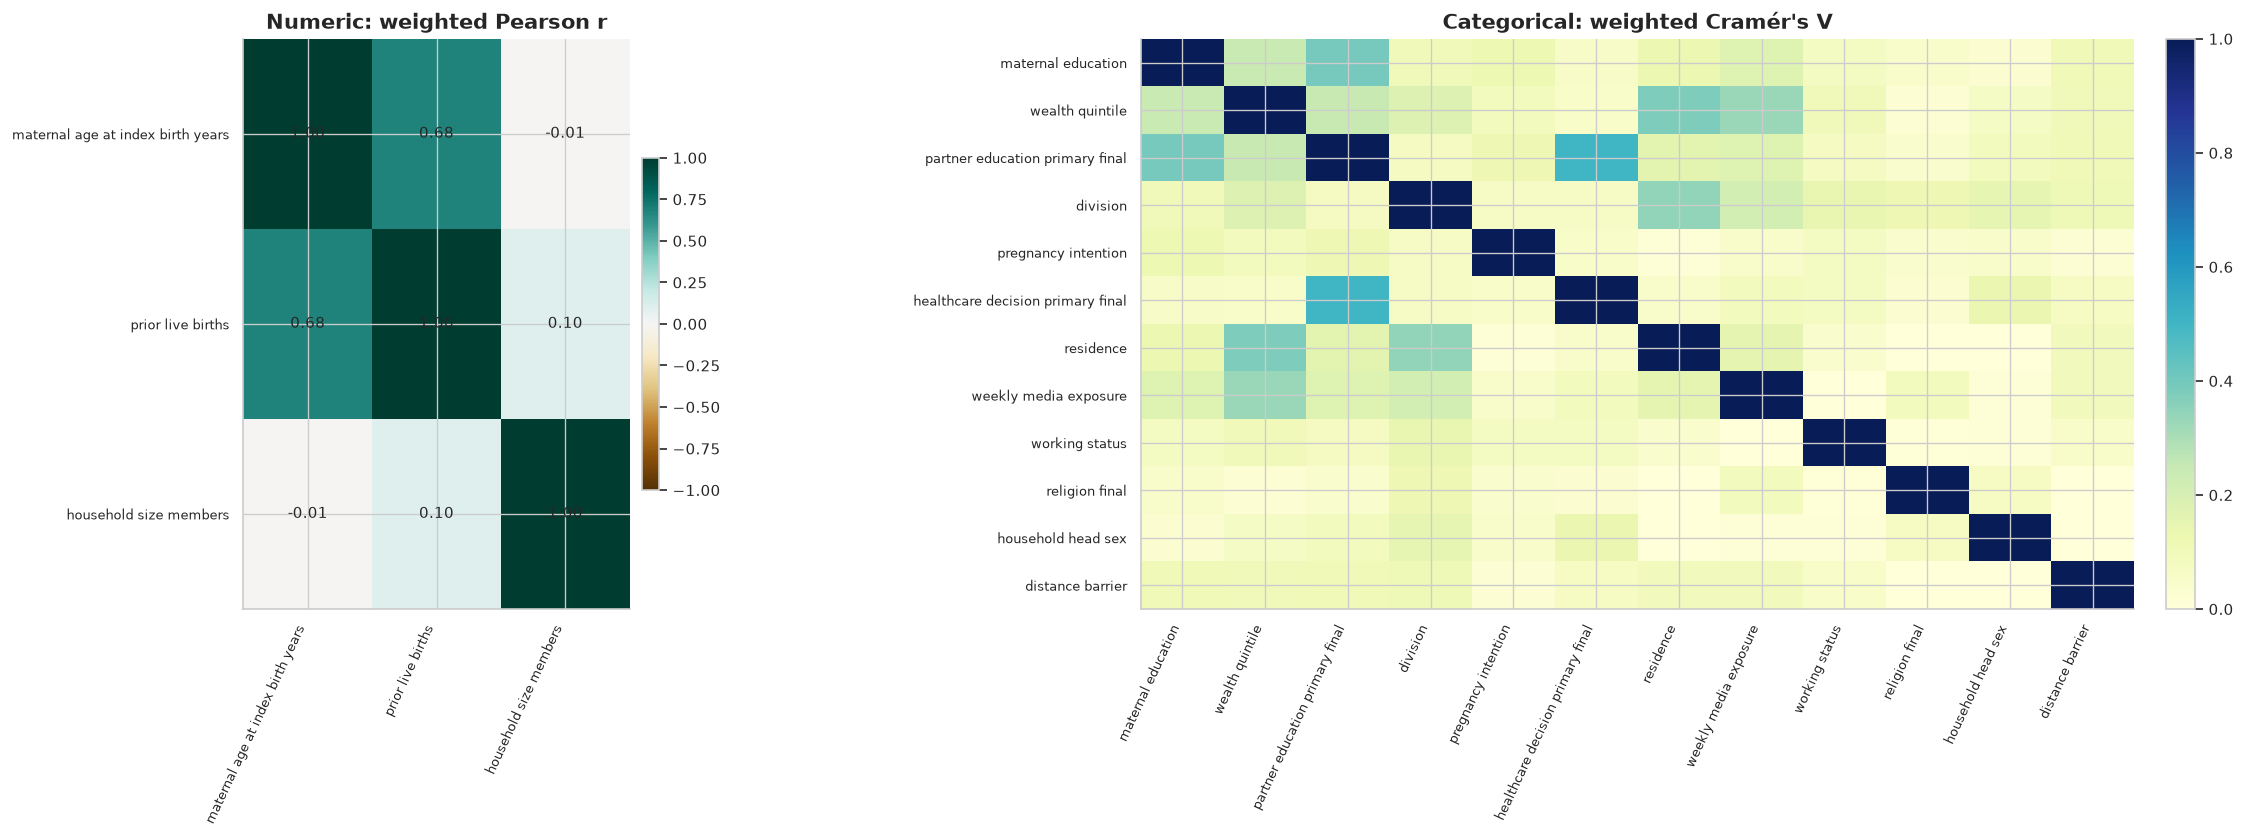

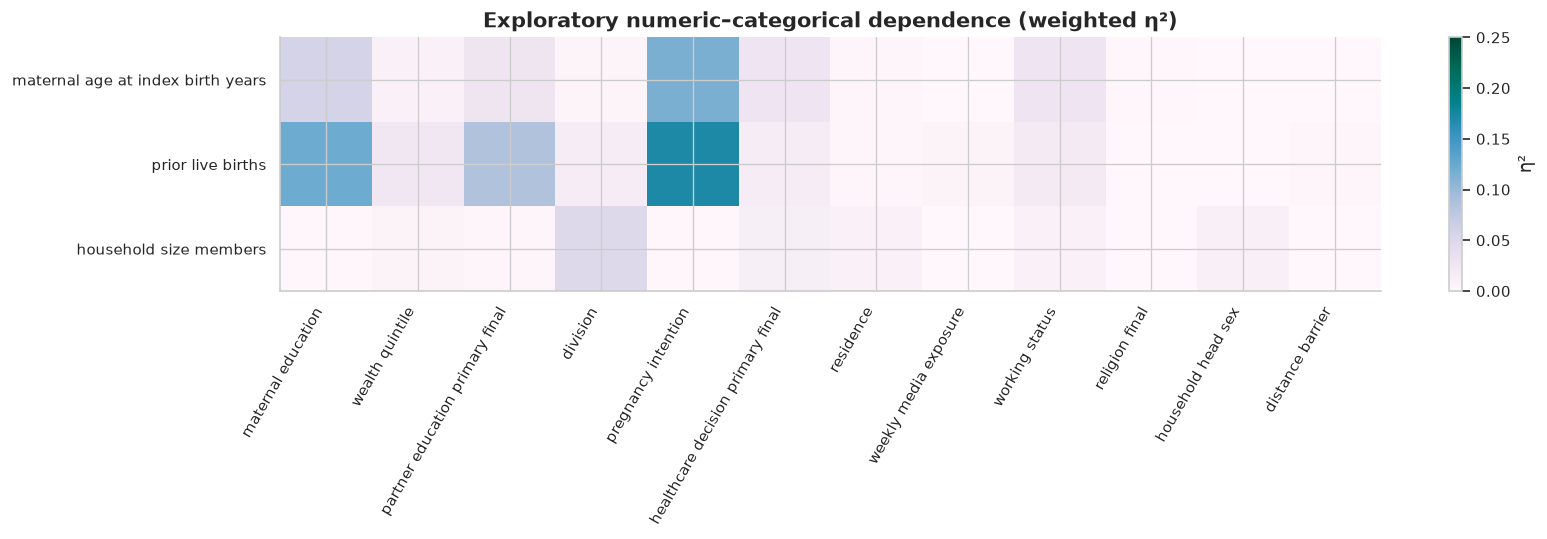

Predictor dependence tables and heatmaps saved.


In [7]:
# ----------------------------------------------------------------------------------------------
# Numeric Pearson/Spearman, categorical Cramer's V, and mixed-type correlation ratio
# ----------------------------------------------------------------------------------------------
def weighted_cramers_v(c1, c2):
    table = pd.crosstab(eda[c1].astype(str), eda[c2].astype(str), values=eda.SURVEY_WEIGHT,
                        aggfunc="sum").fillna(0.0).to_numpy(float)
    N = table.sum()
    expect = np.outer(table.sum(1), table.sum(0)) / N
    chi2 = np.nansum((table-expect)**2 / np.where(expect > 0, expect, np.nan))
    return math.sqrt(max(chi2 / N, 0) / min(table.shape[0]-1, table.shape[1]-1))

def weighted_eta_sq(num, cat):
    xx = eda[num].to_numpy(float)
    cc = eda[cat].astype(str).to_numpy()
    overall = np.average(xx, weights=w)
    total = np.dot(w, (xx-overall)**2)
    if total < 1e-12: return np.nan
    explained = 0.0
    for level in LEVEL_ORDERS[cat]:
        ix = cc == level
        mu = np.average(xx[ix], weights=w[ix])
        explained += w[ix].sum() * (mu-overall)**2
    return max(0.0, min(1.0, explained/total))

corr = np.zeros((len(NUMERIC), len(NUMERIC)))
spearman = np.zeros_like(corr)
for i, first in enumerate(NUMERIC):
    for j, second in enumerate(NUMERIC):
        corr[i, j] = weighted_correlation(eda[first], eda[second])
        spearman[i, j] = weighted_correlation(
            stats.rankdata(eda[first]), stats.rankdata(eda[second]))
cv = np.ones((len(CATEGORICAL), len(CATEGORICAL)))
for i in range(len(CATEGORICAL)):
    for j in range(i+1, len(CATEGORICAL)):
        cv[i, j] = cv[j, i] = weighted_cramers_v(CATEGORICAL[i], CATEGORICAL[j])
eta = np.array([[weighted_eta_sq(a,b) for b in CATEGORICAL] for a in NUMERIC])

save_csv(pd.DataFrame(corr, index=NUMERIC, columns=NUMERIC).rename_axis("Predictor").reset_index(),
         "12_weighted_numeric_pearson")
save_csv(pd.DataFrame(spearman, index=NUMERIC, columns=NUMERIC).rename_axis("Predictor").reset_index(),
         "13_weighted_numeric_spearman")
save_csv(pd.DataFrame(cv, index=CATEGORICAL, columns=CATEGORICAL).rename_axis("Predictor").reset_index(),
         "14_weighted_categorical_cramers_v")
save_csv(pd.DataFrame(eta, index=NUMERIC, columns=CATEGORICAL).rename_axis("Predictor").reset_index(),
         "15_weighted_numeric_categorical_eta_sq")

fig, axes = plt.subplots(1, 2, figsize=(18, 8.8), gridspec_kw={"width_ratios": [.7, 1.8]})
for ax, data, labels, title, vmin, vmax in [
    (axes[0], corr, NUMERIC, "Numeric: weighted Pearson r", -1, 1),
    (axes[1], cv, CATEGORICAL, "Categorical: weighted Cramér's V", 0, 1)]:
    im = ax.imshow(data, cmap="BrBG" if vmin < 0 else "YlGnBu", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(labels)), [s.replace("_", " ") for s in labels], rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(labels)), [s.replace("_", " ") for s in labels], fontsize=8)
    if len(labels) <= 3:
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j,i,f"{data[i,j]:.2f}",ha="center",va="center",fontsize=9)
    fig.colorbar(im, ax=ax, fraction=.04, pad=.03)
    ax.set_title(title)
fig.subplots_adjust(left=.07, right=.98, bottom=.36, top=.9, wspace=.65)
save_plot(fig, "04_predictor_association_heatmaps")

fig, ax = plt.subplots(figsize=(14, 4.6))
im = ax.imshow(eta, cmap="PuBuGn", vmin=0, vmax=max(.25, np.nanmax(eta)), aspect="auto")
ax.set_yticks(range(len(NUMERIC)), [s.replace("_", " ") for s in NUMERIC])
ax.set_xticks(range(len(CATEGORICAL)), [s.replace("_", " ") for s in CATEGORICAL], rotation=60, ha="right")
ax.set_title("Exploratory numeric–categorical dependence (weighted η²)")
fig.colorbar(im, ax=ax, label="η²")
fig.tight_layout(); save_plot(fig, "05_mixed_predictor_dependence")
print("Predictor dependence tables and heatmaps saved.")

## 08 | Exploratory design-adjusted outcome associations

Global Wald tests compare outcome-specific proportions across categorical groups and weighted numeric means across outcome groups. The test uses analytic-sample PSU influences, not a Rao–Scott correction. Tests are exploratory and adjusted for multiplicity with Benjamini–Hochberg FDR.

In [8]:
# ----------------------------------------------------------------------------------------------
# Linearized influence contrasts and exploratory multi-df design Wald statistics
# ----------------------------------------------------------------------------------------------
def domain_mean_influence(v, group_mask):
    arr = np.asarray(v, float)
    mask = np.asarray(group_mask, bool)
    den = w[mask].sum()
    if den <= 0:
        return np.nan, np.zeros(n)
    estimate = float(np.dot(w[mask], arr[mask]) / den)
    IF = np.zeros(n)
    IF[mask] = w[mask] * (arr[mask] - estimate) / den
    return estimate, IF

def wald_from_contrasts(estimates, influence_vectors):
    diff = np.asarray(estimates, float)
    ic = np.column_stack(influence_vectors)
    cov = influence_covariance(ic)
    rank = int(np.linalg.matrix_rank(cov, tol=1e-11))
    if rank == 0 or rank != len(diff):
        return {"F": np.nan, "DF1": rank, "DF2": DESIGN_DF,
                "p": np.nan, "Reason": "Singular or non-estimable covariance"}
    F = float(diff @ np.linalg.pinv(cov, rcond=1e-10) @ diff / rank)
    return {"F": F, "DF1": rank, "DF2": DESIGN_DF,
            "p": float(stats.f.sf(F, rank, DESIGN_DF)), "Reason": "Exploratory analytic-PSU Wald F"}

association_tests = []
for feature in CATEGORICAL:
    val = eda[feature].astype(str).to_numpy()
    groups = LEVEL_ORDERS[feature]
    observed = pd.crosstab(eda[feature].astype(str), eda["ANC_CLASS"])
    too_sparse = (observed.reindex(index=groups, columns=[0,1,2], fill_value=0) < 5).any().any()
    if too_sparse:
        association_tests.append({"Predictor": feature, "Type": "Categorical", "F": np.nan,
                                  "DF1": np.nan, "DF2": DESIGN_DF, "p": np.nan,
                                  "Reason": "Skipped: one or more category-by-outcome cells <5"})
        continue
    ref = max(groups, key=lambda v: int((val==v).sum()))
    differences, infl = [], []
    for group in groups:
        if group == ref: continue
        for cls in [0,2]:
            e1, i1 = domain_mean_influence((y == cls).astype(float), val == group)
            e0, i0 = domain_mean_influence((y == cls).astype(float), val == ref)
            differences.append(e1 - e0); infl.append(i1 - i0)
    test = wald_from_contrasts(differences, infl)
    association_tests.append({"Predictor": feature, "Type": "Categorical", **test})

for feature in NUMERIC:
    arr = eda[feature].to_numpy(float)
    e1, i1 = domain_mean_influence(arr, y == 1)
    diffs, infl = [], []
    for cls in [0,2]:
        ek, ik = domain_mean_influence(arr, y == cls)
        diffs.append(ek - e1); infl.append(ik - i1)
    test = wald_from_contrasts(diffs, infl)
    association_tests.append({"Predictor": feature, "Type": "Numeric", **test})

tests = pd.DataFrame(association_tests)
# Benjamini–Hochberg adjusted p-values for estimable exploratory comparisons.
pval = tests["p"].to_numpy(float)
valid = np.where(np.isfinite(pval))[0]
q = np.full(len(pval), np.nan)
if len(valid):
    ord_idx = valid[np.argsort(pval[valid])]
    ranked = pval[ord_idx] * len(valid) / np.arange(1, len(valid)+1)
    q[ord_idx] = np.clip(np.minimum.accumulate(ranked[::-1])[::-1], 0, 1)
tests["BH_FDR_q"] = q
save_csv(tests, "16_exploratory_global_wald_and_bh_q")
print("Exploratory Wald tests: estimable", len(valid), "of", len(PREDICTORS))
display(tests[["Predictor", "F", "DF1", "p", "BH_FDR_q", "Reason"]].round(4))

Exploratory Wald tests: estimable 12 of 15


,Predictor,F,DF1,p,BH_FDR_q,Reason
0,maternal_education,NaN,NaN,NaN,NaN,Skipped: one or more category-by-outcome cells <5
1,wealth_quintile,33.2863,8.0,0.0000,0.0000,Exploratory analytic-PSU Wald F
2,partner_education_primary_final,NaN,NaN,NaN,NaN,Skipped: one or more category-by-outcome cells <5
3,division,4.1417,14.0,0.0000,0.0000,Exploratory analytic-PSU Wald F
4,pregnancy_intention,3.5922,4.0,0.0066,0.0088,Exploratory analytic-PSU Wald F
5,healthcare_decision_primary_final,NaN,NaN,NaN,NaN,Skipped: one or more category-by-outcome cells <5
6,residence,11.9544,2.0,0.0000,0.0000,Exploratory analytic-PSU Wald F
7,weekly_media_exposure,39.8778,2.0,0.0000,0.0000,Exploratory analytic-PSU Wald F
8,working_status,1.2058,2.0,0.3001,0.3274,Exploratory analytic-PSU Wald F
9,religion_final,1.2651,2.0,0.2829,0.3274,Exploratory analytic-PSU Wald F


## 09 | Geographic and socioeconomic subgroup comparisons

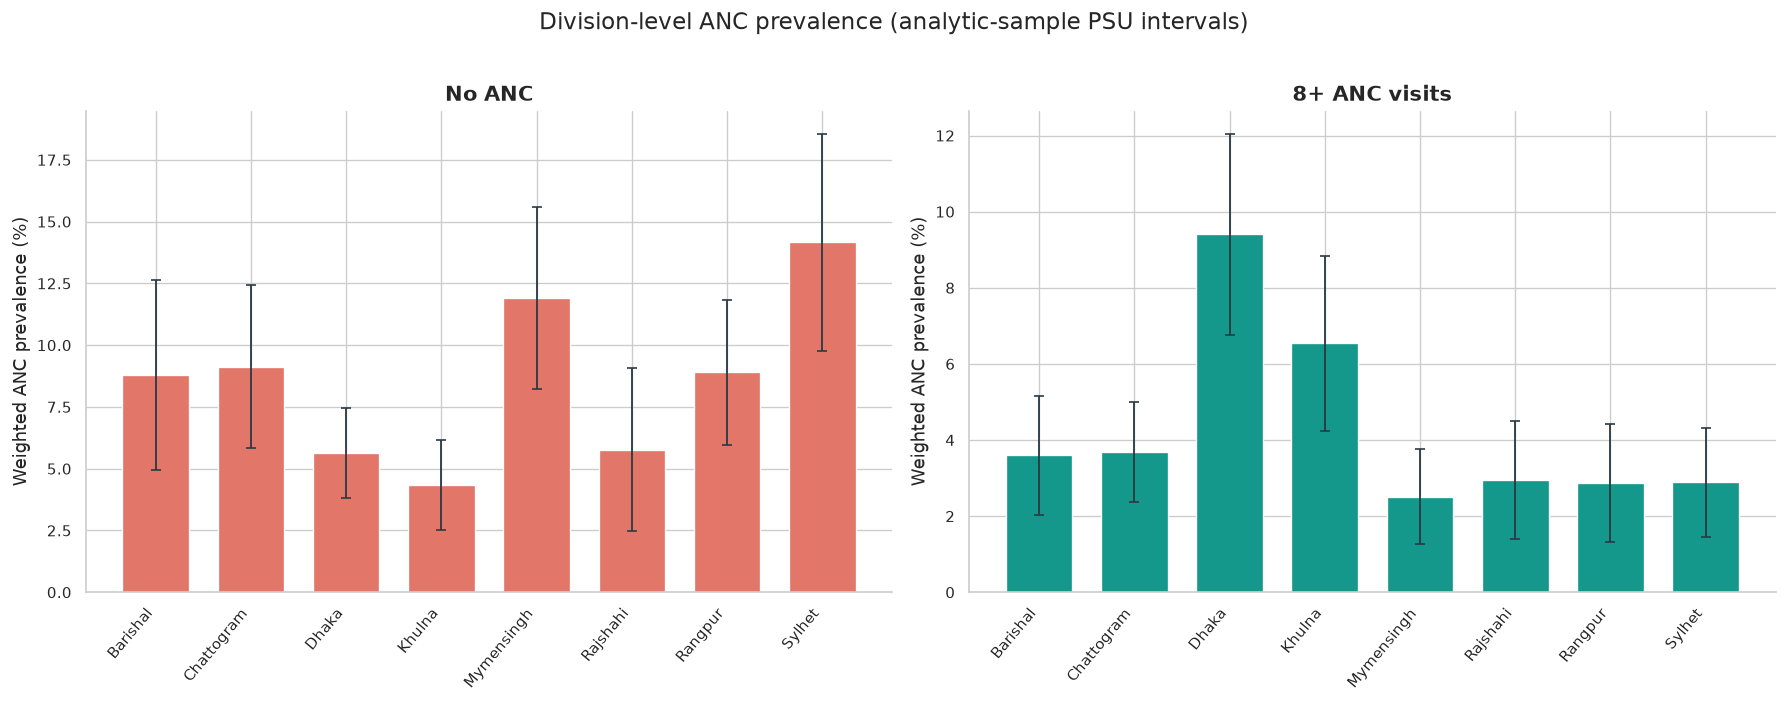

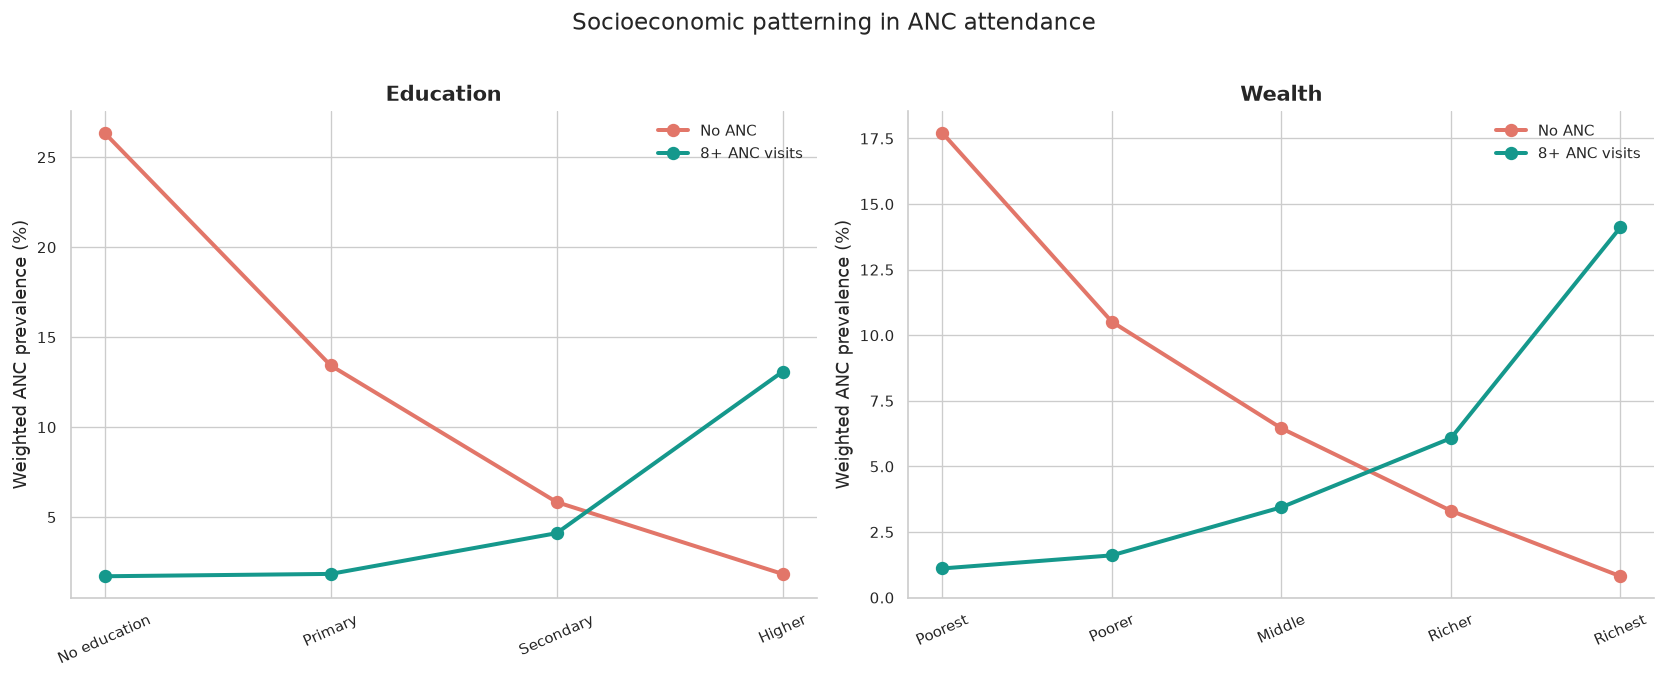

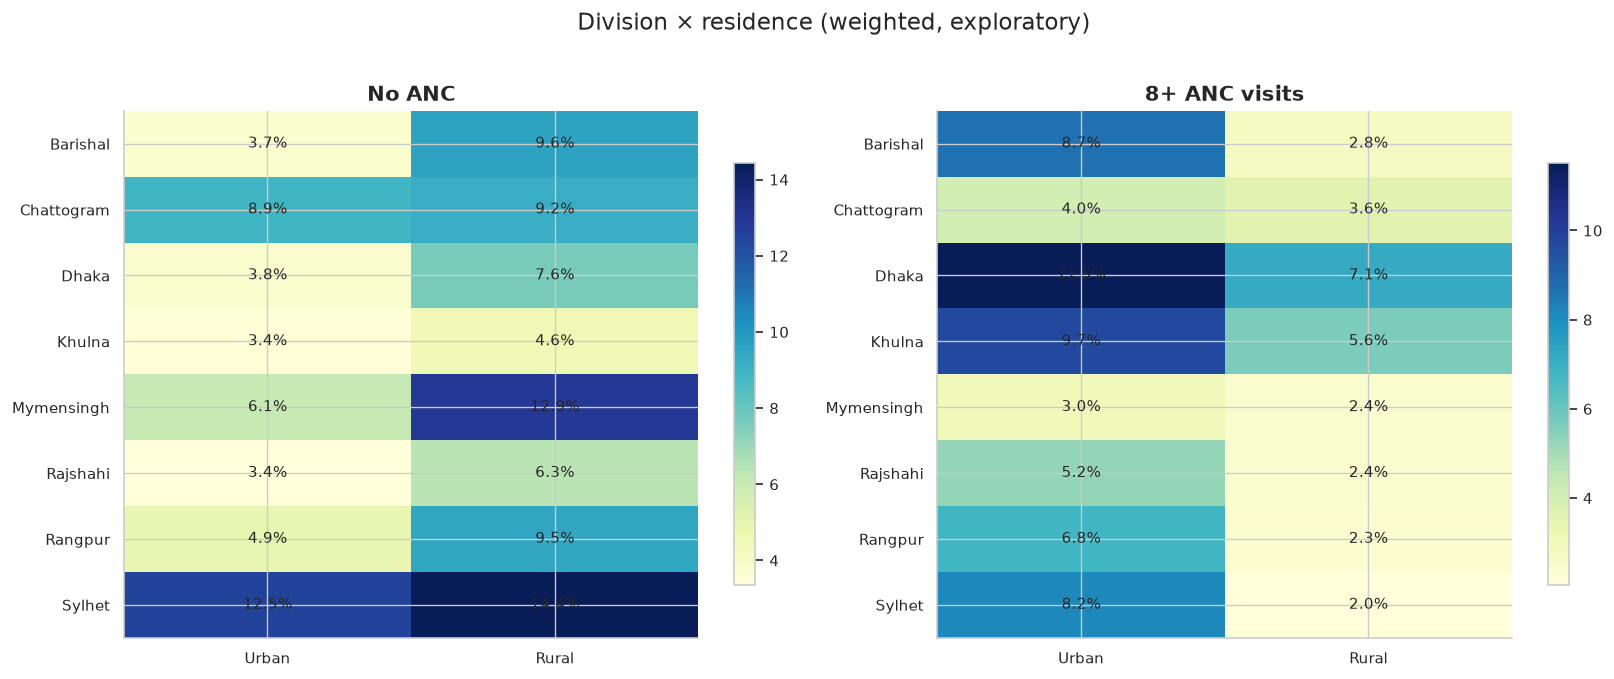

Geography and socioeconomic subgroup reports saved.


In [9]:
# ----------------------------------------------------------------------------------------------
# Division, residence, education, and wealth outcome summaries with subgroup diagnostics
# ----------------------------------------------------------------------------------------------
def profile_by(column, levels=None):
    vals = eda[column].astype(str).to_numpy()
    groups = LEVEL_ORDERS[column] if levels is None else levels
    rows = []
    for level in groups:
        mask = vals == level
        for k in (0, 1, 2):
            e = weighted_estimate((y == k).astype(float), mask)
            rows.append({"Variable": column, "Group": level, "Class": k,
                         "N": e["N"], "Cell_N": int((mask & (y == k)).sum()),
                         "Percent": 100 * e["Estimate"], "Lower": 100 * e["LCL"],
                         "Upper": 100 * e["UCL"], "Group_Kish_N": e["Kish_N"],
                         "Group_PSU_N": e["PSU_N"],
                         "Small_Group": e["N"] < 30,
                         "Small_Cell": int((mask & (y == k)).sum()) < 5})
    return pd.DataFrame(rows)

geo = profile_by("division")
residence = profile_by("residence")
education = profile_by("maternal_education")
wealth = profile_by("wealth_quintile")
for name, table in [("division",geo),("residence",residence),
                    ("maternal_education",education),("wealth_quintile",wealth)]:
    save_csv(table, f"17_group_{name}")

# Division-by-residence descriptive interaction grid.
subgroups = []
for div in LEVEL_ORDERS["division"]:
    for urban in LEVEL_ORDERS["residence"]:
        ix = (eda.division == div).to_numpy() & (eda.residence == urban).to_numpy()
        for k in (0, 2):
            e = weighted_estimate((y == k).astype(float), ix)
            subgroups.append({"Division": div, "Residence": urban, "Class": k,
                              "N": e["N"], "Cell_N": int((ix & (y == k)).sum()),
                              "Weighted_Pct": 100 * e["Estimate"],
                              "CI_Low": 100 * e["LCL"], "CI_High": 100 * e["UCL"],
                              "Sparse": int((ix & (y == k)).sum()) < 5})
geo_res = pd.DataFrame(subgroups)
save_csv(geo_res, "18_division_by_residence")

socio = []
for schooling in LEVEL_ORDERS["maternal_education"]:
    for quintile in LEVEL_ORDERS["wealth_quintile"]:
        ix = (eda.maternal_education == schooling).to_numpy() & (eda.wealth_quintile == quintile).to_numpy()
        for k in (0,2):
            e = weighted_estimate((y == k).astype(float), ix)
            socio.append({"Education":schooling, "Wealth":quintile, "Class":k,
                          "N":e["N"], "Cell_N":int((ix & (y==k)).sum()),
                          "Weighted_Pct":100*e["Estimate"], "CI_Low":100*e["LCL"],
                          "CI_High":100*e["UCL"], "Sparse":int((ix & (y==k)).sum()) < 5})
socio = pd.DataFrame(socio)
save_csv(socio, "19_education_by_wealth")

fig, axes = plt.subplots(1,2,figsize=(15,5.7))
for ax, cls in zip(axes,[0,2]):
    dat=geo[geo.Class==cls].set_index("Group").reindex(LEVEL_ORDERS["division"])
    arr=np.arange(len(dat))
    ax.bar(arr,dat.Percent,color=COLORS[cls],width=.7)
    yerr=[np.maximum(0, dat.Percent-dat.Lower),np.maximum(0, dat.Upper-dat.Percent)]
    ax.errorbar(arr,dat.Percent,yerr=yerr,fmt="none",color="#2A3A44",capsize=3,linewidth=1.1)
    ax.set_xticks(arr, dat.index,rotation=50,ha="right")
    ax.set_ylabel("Weighted ANC prevalence (%)")
    ax.set_title(CLASS_TEXT[cls])
fig.suptitle("Division-level ANC prevalence (analytic-sample PSU intervals)",fontsize=14,y=1.02)
fig.tight_layout();save_plot(fig,"06_division_prevalence_with_intervals")

fig,axes=plt.subplots(1,2,figsize=(14,5.5))
for ax, col, levels, title in [(axes[0],"maternal_education",LEVEL_ORDERS["maternal_education"],"Education"),
                                (axes[1],"wealth_quintile",LEVEL_ORDERS["wealth_quintile"],"Wealth")]:
    vals=profile_by(col)
    for k in [0,2]:
        tab=vals[vals.Class==k].set_index("Group").reindex(levels)
        ax.plot(levels,tab.Percent,marker="o",markersize=7,linewidth=2.4,color=COLORS[k],label=CLASS_TEXT[k])
    ax.set_ylabel("Weighted ANC prevalence (%)")
    ax.set_title(title)
    ax.tick_params(axis="x",rotation=24)
    ax.legend(frameon=False,fontsize=9)
fig.suptitle("Socioeconomic patterning in ANC attendance",y=1.02,fontsize=14)
fig.tight_layout();save_plot(fig,"07_socioeconomic_gradients")

fig,axs=plt.subplots(1,2,figsize=(14,5.5))
for ax,cls in zip(axs,[0,2]):
    mat=geo_res[geo_res.Class==cls].pivot(index="Division",columns="Residence",values="Weighted_Pct")
    mat=mat.reindex(index=LEVEL_ORDERS["division"],columns=LEVEL_ORDERS["residence"])
    image=ax.imshow(mat,aspect="auto",cmap="YlGnBu")
    for (r,c), z in np.ndenumerate(mat.to_numpy()):
        ax.text(c,r,f"{z:.1f}%",ha="center",va="center",fontsize=9)
    ax.set_xticks(range(2),mat.columns); ax.set_yticks(range(8),mat.index)
    ax.set_title(CLASS_TEXT[cls]);fig.colorbar(image,ax=ax,shrink=.8)
fig.suptitle("Division × residence (weighted, exploratory)",fontsize=14,y=1.02)
fig.tight_layout();save_plot(fig,"08_division_residence_heatmaps")
print("Geography and socioeconomic subgroup reports saved.")

## 10 | Descriptive feature-space projection

An unsupervised standardized numeric/one-hot projection is used only to display possible clustering and overlap; it does not alter predictors or estimate predictive performance.

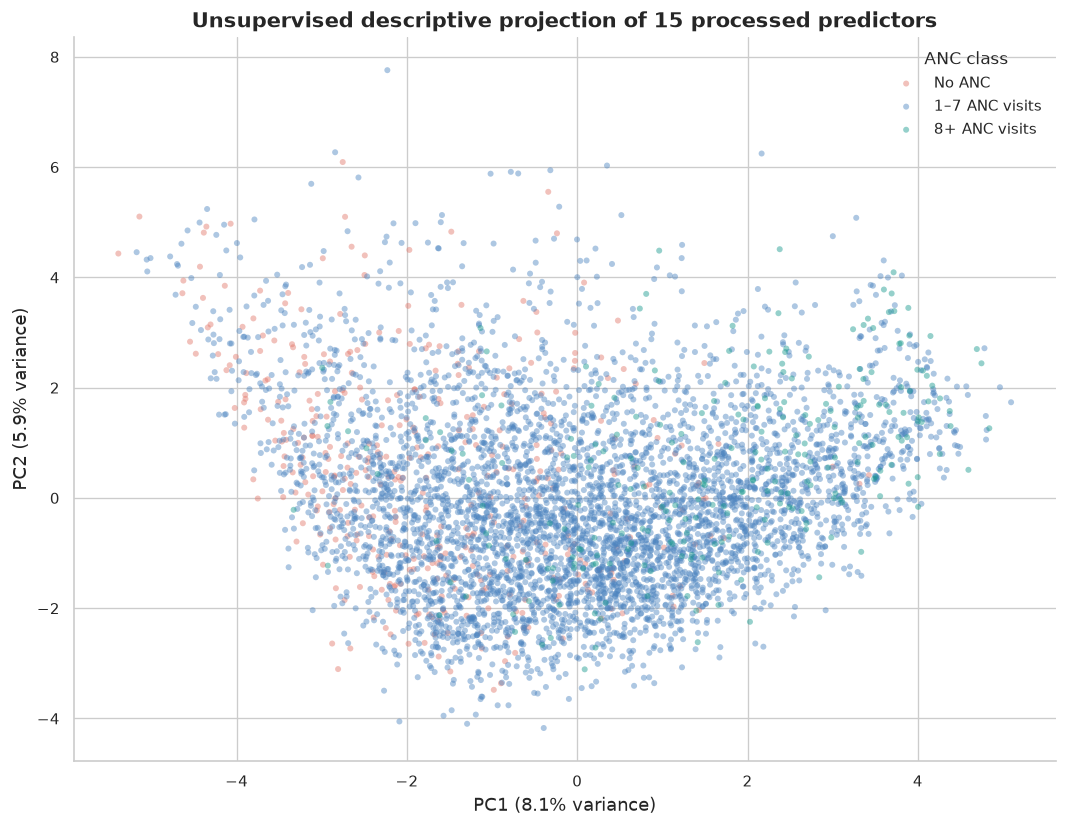

Descriptive projection plotted; no individual-level coordinates exported.


In [10]:
# ----------------------------------------------------------------------------------------------
# Descriptive principal-component projection of the finalized predictor set
# ----------------------------------------------------------------------------------------------
encoded = pd.get_dummies(eda[CATEGORICAL], dtype=float)
Xproj = np.column_stack([eda[NUMERIC].to_numpy(float), encoded.to_numpy(float)])
Xproj -= Xproj.mean(axis=0, keepdims=True)
scale = Xproj.std(axis=0, ddof=0)
Xproj = Xproj[:, scale > 1e-12] / scale[scale > 1e-12]
U, S, VT = np.linalg.svd(Xproj, full_matrices=False)
projection = U[:, :2] * S[:2]
explained = S[:2]**2 / np.sum(S*S)
fig, ax = plt.subplots(figsize=(9,7))
for cls in range(3):
    mask = y == cls
    ax.scatter(projection[mask,0], projection[mask,1], color=COLORS[cls], s=13,
               alpha=.45, label=CLASS_TEXT[cls], edgecolors="none", rasterized=True)
ax.set_xlabel(f"PC1 ({100*explained[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({100*explained[1]:.1f}% variance)")
ax.set_title("Unsupervised descriptive projection of 15 processed predictors")
ax.legend(title="ANC class",frameon=False)
fig.tight_layout();save_plot(fig,"09_exploratory_predictor_projection")
save_csv(pd.DataFrame({"Principal_Component":[1,2],"Explained_Variance_Ratio":explained}),
         "20_descriptive_projection_variance")
print("Descriptive projection plotted; no individual-level coordinates exported.")

## 11 | Bangladesh division choropleths

Administrative polygons are retrieved from the Bangladesh DGHS GIS division feature service, with geoBoundaries as an alternative. Eight-division identity and geographic coordinate checks are mandatory. Validated polygons are cached under the EDA output directory. If geometry is inaccessible, geographic tables and regional rate figures remain available; unverified boundaries are never plotted.

findfont: Failed to find font weight semibold, now using 700.


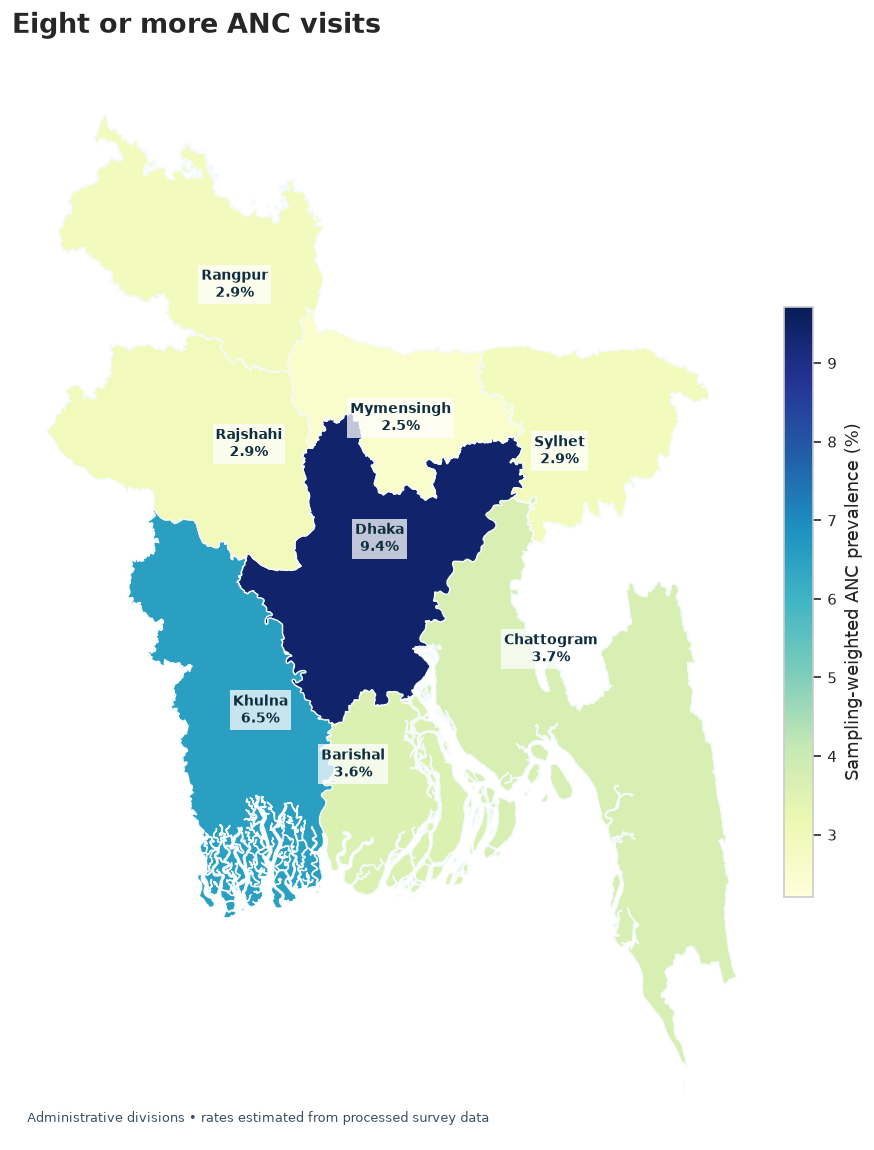

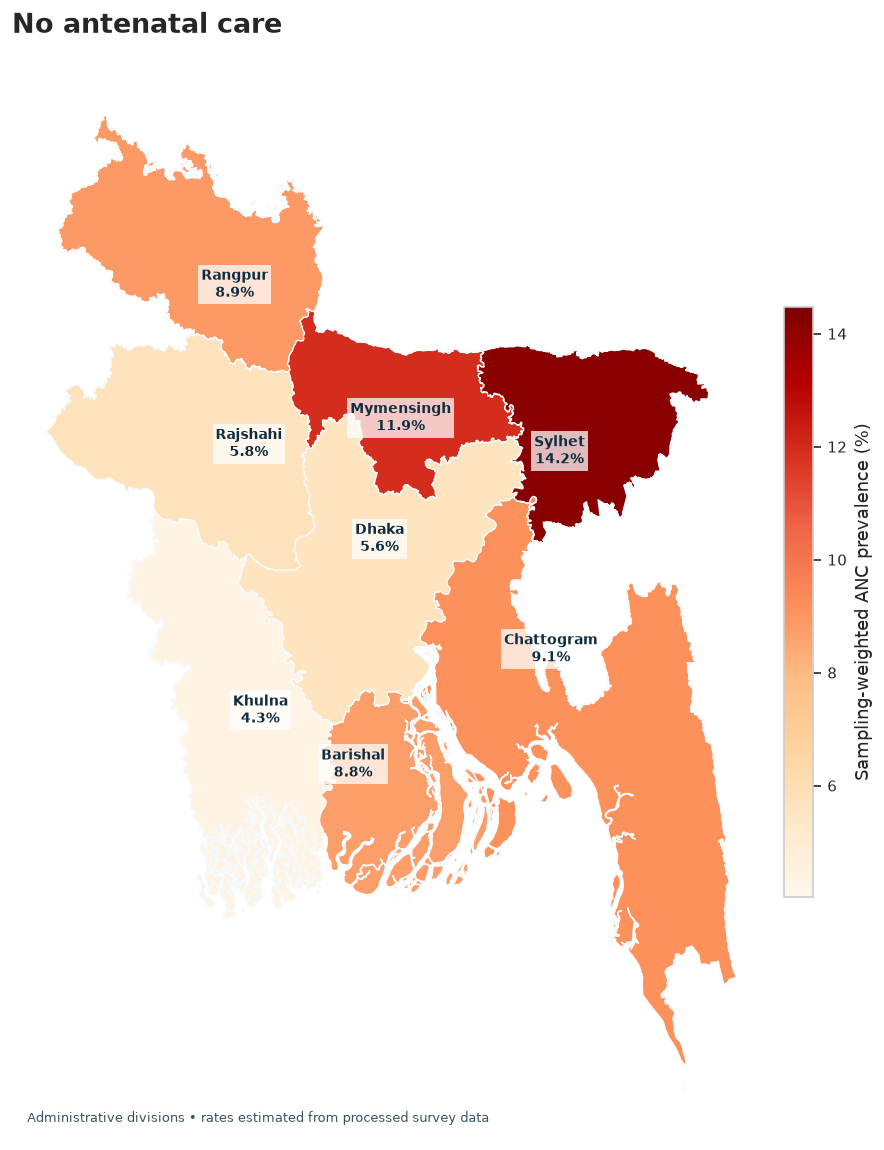

Map status: PASS: two division choropleths


In [11]:
# ----------------------------------------------------------------------------------------------
# Eight-division boundary validation, cached geometries, and sampling-weighted maps
# ----------------------------------------------------------------------------------------------
ALIASES = {"barisal": "Barishal", "barishal": "Barishal",
           "chittagong": "Chattogram", "chattogram": "Chattogram"}
DIVISIONS = set(LEVEL_ORDERS["division"])

def normalize_division(value):
    s = unicodedata.normalize("NFKD", str(value)).strip().lower().replace(" division", "")
    return ALIASES.get(s, next((d for d in DIVISIONS if d.lower() == s), None))

def boundary_features(geojson):
    if geojson.get("type") != "FeatureCollection":
        raise ValueError("Map boundary data are not a GeoJSON FeatureCollection.")
    found = {}
    for item in geojson.get("features", []):
        prop = item.get("properties", {})
        possible = [prop.get(c) for c in ["adm1_en", "ADM1_EN", "shapeName", "NAME_1", "name", "Name"]]
        name = next((normalize_division(x) for x in possible if normalize_division(x)), None)
        if name is None or name in found:
            raise ValueError(f"Unrecognized or duplicated ADM1 division: {possible}")
        geom = item.get("geometry", {})
        if geom.get("type") not in ("Polygon", "MultiPolygon"):
            raise ValueError(f"Invalid geometry for {name}")
        polygons = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
        vertex_count = 0
        for rings in polygons:
            if not rings or len(rings[0]) < 4:
                raise ValueError(f"Invalid polygon ring for {name}")
            coords = np.asarray(rings[0], float)
            if not np.isfinite(coords).all():
                raise ValueError(f"Non-finite coordinates for {name}")
            if not (np.all((coords[:,0] >= 87) & (coords[:,0] <= 94)) and
                    np.all((coords[:,1] >= 20) & (coords[:,1] <= 27))):
                raise ValueError(f"Polygon outside Bangladesh coordinate bounds: {name}")
            vertex_count += len(coords)
        found[name] = (geom, vertex_count)
    if set(found) != DIVISIONS:
        raise ValueError(f"Eight-division map mismatch: missing={DIVISIONS-set(found)}; extra={set(found)-DIVISIONS}")
    return found

def download_json(url, timeout=28):
    req = urllib.request.Request(url, headers={"User-Agent": "BDHS-ANC-EDA/1.0"})
    with urllib.request.urlopen(req, timeout=timeout) as response:
        content = response.read(15_000_001)
    if len(content) > 15_000_000:
        raise ValueError("GeoJSON response exceeds maximum expected size")
    return json.loads(content.decode("utf-8-sig"))

MAP_CACHE = OUT["06_assets"] / "Bangladesh_ADM1_8divisions_verified.geojson"
MAP_SOURCE = OUT["06_assets"] / "Bangladesh_ADM1_source.json"

def load_division_polygons():
    if MAP_CACHE.exists():
        try:
            geom = json.loads(MAP_CACHE.read_text(encoding="utf-8"))
            boundary_features(geom)
            return geom, "Validated cached geometry"
        except (OSError, ValueError, KeyError, json.JSONDecodeError):
            warnings.warn("Map cache does not pass geographic validation; fetching a verified source.")

    gov_url = (
        "https://gis.dghs.gov.bd/server/rest/services/Hosted/"
        "bgd_admbnda_adm1_bbs_20201113/FeatureServer/0/query"
        "?where=1%3D1&outFields=adm1_en&f=geojson&outSR=4326"
    )
    sources = [("Bangladesh DGHS/BBS ADM1 GIS", gov_url)]
    metadata_url = "https://www.geoboundaries.org/api/current/gbOpen/BGD/ADM1/"
    try:
        metadata = download_json(metadata_url)
        if str(metadata.get("admUnitCount")) == "8":
            for field in ["simplifiedGeometryGeoJSON", "gjDownloadURL"]:
                link = metadata.get(field)
                if link and str(link).startswith("https://"):
                    sources.append(("geoBoundaries BGD ADM1", link))
    except Exception:
        pass
    errors = []
    for origin, url in sources:
        try:
            geom = download_json(url)
            boundary_features(geom)
            MAP_CACHE.write_text(json.dumps(geom, ensure_ascii=False), encoding="utf-8")
            MAP_SOURCE.write_text(json.dumps({"Source":origin,"URL":url,
                "Retrieved_UTC":datetime.now(timezone.utc).isoformat()}, indent=2), encoding="utf-8")
            return geom, origin
        except Exception as exc:
            errors.append(f"{origin}: {type(exc).__name__}: {str(exc)[:120]}")
    raise RuntimeError("Eight-division boundary download unavailable. " + " | ".join(errors))

# Longitude/latitude plotting uses a cosine correction for the map's mean latitude.
def polygon_area(ring):
    pts = np.asarray(ring, float)
    return abs(float(.5 * (np.dot(pts[:,0], np.roll(pts[:,1], -1)) -
                             np.dot(pts[:,1], np.roll(pts[:,0], -1)))))

def map_divisions(geom, target, filename, title):
    features = boundary_features(geom)
    map_rates = (geo[geo.Class == target].set_index("Group")["Percent"]
                 .reindex(LEVEL_ORDERS["division"]).to_dict())
    colormap = plt.get_cmap("YlGnBu" if target == 2 else "OrRd")
    vals = np.array(list(map_rates.values()), dtype=float)
    norm = mcolors.Normalize(vmin=max(0, vals.min() - .3), vmax=vals.max() + .3)
    patches, patch_val, labels = [], [], []
    for name in LEVEL_ORDERS["division"]:
        geometry = features[name][0]
        groups = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
        shells = [np.asarray(poly[0], float) for poly in groups]
        for shell in shells:
            patches.append(Polygon(shell, closed=True))
            patch_val.append(map_rates[name])
        large = max(shells, key=polygon_area)
        center = np.mean(large[:-1], axis=0)
        labels.append((name, center, map_rates[name]))

    fig, ax = plt.subplots(figsize=(9.6, 11.6), facecolor="white")
    collection = PatchCollection(patches, cmap=colormap, norm=norm,
                                 edgecolor="#F5FAFC", linewidth=.8, antialiased=True)
    collection.set_array(np.array(patch_val, dtype=float))
    ax.add_collection(collection)
    for name, point, v in labels:
        ax.text(point[0], point[1], f"{name}\n{v:.1f}%", color="#102E41", ha="center", va="center",
                fontsize=8.5, fontweight="semibold",
                bbox={"facecolor":"white", "alpha":.74, "pad":1.7, "edgecolor":"none"})
    ax.autoscale_view()
    ax.set_aspect(1 / np.cos(np.deg2rad(23.7)))
    ax.set_axis_off()
    cbar = fig.colorbar(collection, ax=ax, fraction=.033, pad=.015, shrink=.75)
    cbar.set_label("Sampling-weighted ANC prevalence (%)")
    ax.set_title(title, fontsize=16, loc="left", pad=20, weight="bold")
    ax.text(.02, .015, "Administrative divisions • rates estimated from processed survey data",
            transform=ax.transAxes, fontsize=8, color="#395064")
    save_plot(fig, filename, folder="04_maps")

MAP_STATUS = "Not available"
try:
    geometry, source_label = load_division_polygons()
    _map_info = boundary_features(geometry)
    geo_metadata = pd.DataFrame([{"Division": k, "Vertices": v[1], "Source": source_label}
                                 for k,v in sorted(_map_info.items())])
    save_csv(geo_metadata, "21_map_boundary_QC", "01_qc")
    map_divisions(geometry, 2, "10_BDHS_eight_plus_ANC_choropleth", "Eight or more ANC visits")
    map_divisions(geometry, 0, "11_BDHS_no_ANC_choropleth", "No antenatal care")
    MAP_STATUS = "PASS: two division choropleths"
except Exception as exc:
    MAP_STATUS = f"Unavailable: {str(exc)[:250]}"
    warnings.warn(MAP_STATUS)

(OUT["05_reports"] / "map_status.json").write_text(
    json.dumps({"Status":MAP_STATUS, "Verified_Divisions": sorted(DIVISIONS),
                "Expected_Map_Cache":str(MAP_CACHE)}, indent=2), encoding="utf-8")
print("Map status:", MAP_STATUS)

## 12 | Publication-style baseline tables and descriptive integrity checks

In [12]:
# ----------------------------------------------------------------------------------------------
# Weighted respondent characteristics and diagnostic audit without predictor modification
# ----------------------------------------------------------------------------------------------
table1 = []
for item in NUMERIC:
    x = eda[item].to_numpy(float)
    est = weighted_estimate(x, interval=False)
    table1.append({"Variable":item, "Level":"Mean (SD)", "N":n,
                   "Unweighted":"{:.2f} ({:.2f})".format(x.mean(), x.std(ddof=1)),
                   "Weighted":"{:.2f} [95% CI {:.2f}–{:.2f}]".format(est["Estimate"],est["LCL"],est["UCL"]),
                   "Statistic":"Descriptive weighted mean"})
for item in CATEGORICAL:
    for level in LEVEL_ORDERS[item]:
        idx = (eda[item] == level).to_numpy()
        est = weighted_estimate(idx.astype(float))
        table1.append({"Variable":item, "Level":level,"N":int(idx.sum()),
                       "Unweighted":f"{int(idx.sum())} ({100*idx.mean():.1f}%)",
                       "Weighted":f"{100*est['Estimate']:.1f}% [95% CI {100*est['LCL']:.1f}–{100*est['UCL']:.1f}]",
                       "Statistic":"Descriptive weighted percentage"})
baseline = pd.DataFrame(table1)
save_csv(baseline, "22_publication_baseline_table")

qc = pd.DataFrame([
    {"Check":"Complete processed master", "Observed":str(eda.shape), "Status":"PASS"},
    {"Check":"Unique respondents", "Observed":str(eda.CASEID.nunique()), "Status":"PASS"},
    {"Check":"Unique observation indices", "Observed":str(eda._ROW_ID.nunique()), "Status":"PASS"},
    {"Check":"Primary predictors", "Observed":str(len(PREDICTORS)), "Status":"PASS"},
    {"Check":"Unresolved missingness", "Observed":str(int(eda[PREDICTORS].isna().sum().sum())), "Status":"PASS"},
    {"Check":"ANC class frequencies", "Observed":str(eda.ANC_CLASS.value_counts().sort_index().to_dict()), "Status":"PASS"},
    {"Check":"Survey-design cells", "Observed":f"{NPSU} PSUs; {NSTRATA} strata", "Status":"PASS"},
    {"Check":"Partner education structural unavailable", "Observed":str(int((eda.partner_education_primary_final=="No current partner; partner education unavailable").sum())), "Status":"PASS"},
    {"Check":"Partner education nonreporting", "Observed":str(int((eda.partner_education_primary_final=="Partner education not reported").sum())), "Status":"PASS"},
    {"Check":"Sparse outcome-category cells", "Observed":str(int(sparse.Flag_Cell_Below_5.sum())), "Status":"REVIEW"},
    {"Check":"Map boundary availability", "Observed":MAP_STATUS, "Status":"PASS" if MAP_STATUS.startswith("PASS") else "OPTIONAL"},
    {"Check":"Full original-design domain variance", "Observed":"Not estimable from primary master alone", "Status":"LIMITATION"},
])
save_csv(qc, "23_final_qc_summary", "01_qc")

diagnostics = pd.DataFrame([
    ["Class imbalance", f"8+ ANC visits: {int((y==2).sum())} of {n}",
     "Interpret small subgroup estimates with care"],
    ["Small cells", f"{int(sparse.Flag_Cell_Below_5.sum())} cells with unweighted n < 5",
     "Do not interpret unstable percentage contrasts as precise"],
    ["Marginal normality", "Normality diagnostics performed on three numeric predictors",
     "Discrete-count predictor normality is not a regression prerequisite"],
    ["Survey inference", f"Analytic master: {NPSU} PSUs across {NSTRATA} strata",
     "CIs and Wald p-values are analytic-sample approximations"],
    ["Structural partner education", "47 structural unavailable and 9 genuine nonreporting",
     "Categories retained separately"],
    ["Socioeconomic timing", "Several predictor values were measured at survey interview",
     "Associations are descriptive rather than prospective causal evidence"],
    ["ANC indicator definition", "Self-reported 8+ ANC visits",
     "Do not equate visits directly with verified WHO contact quality"],
    ["Multiple comparison", "Exploratory Wald P and BH q reported where estimable",
     "No EDA-driven predictor reselection"],
], columns=["Domain", "Evidence", "Interpretation"])
save_csv(diagnostics, "24_methodological_diagnostics", "05_reports")
print("QC table:")
display(qc)

QC table:


,Check,Observed,Status
0,Complete processed master,"(5063, 23)",PASS
1,Unique respondents,5063,PASS
2,Unique observation indices,5063,PASS
3,Primary predictors,15,PASS
4,Unresolved missingness,0,PASS
5,ANC class frequencies,"{0: 403, 1: 4407, 2: 253}",PASS
6,Survey-design cells,672 PSUs; 16 strata,PASS
7,Partner education structural unavailable,47,PASS
8,Partner education nonreporting,9,PASS
9,Sparse outcome-category cells,6,REVIEW


## 13 | Output manifest and immutable-source verification

In [13]:
# ----------------------------------------------------------------------------------------------
# Artifact inventory, reproducibility metadata, and final source integrity
# ----------------------------------------------------------------------------------------------
check(file_hash(PRIMARY_FILE) == SOURCE_SHA256, "Primary processed input changed during analysis.")
files = [{"Directory": name, "File": file.name, "Bytes": file.stat().st_size}
         for name, folder in OUT.items() for file in sorted(folder.iterdir()) if file.is_file()]
file_report = pd.DataFrame(files)
save_csv(file_report, "25_file_inventory", "05_reports")

manifest = {
    "Study": "Bangladesh DHS 2022 antenatal-care processed-primary exploratory analysis",
    "Generated_UTC": datetime.now(timezone.utc).isoformat(),
    "Input_File": str(PRIMARY_FILE), "Input_SHA256": SOURCE_SHA256,
    "Expected_Input_SHA256": EXPECTED_PRIMARY_SHA256, "Expected_Hash_Verified": CHECK_HASH,
    "Analytic_N": n, "Input_Data_Shape": list(eda.shape), "Primary_Predictors": len(PREDICTORS),
    "Numeric_Predictors": NUMERIC, "Categorical_Predictors": CATEGORICAL,
    "Outcome_Counts": {str(k):v for k,v in EXPECTED_CLASS_COUNTS.items()},
    "PSU_Analytic": NPSU, "Strata_Analytic": NSTRATA,
    "Uncertainty_Method": "Stratified cluster Taylor approximation, analytic master PSUs only",
    "Full_Original_Design_Domain_Variance": "Not estimable from primary master alone",
    "Map_Status": MAP_STATUS,
    "Exploratory_Tests": "PSU-based Wald F with BH-adjusted q; not Rao-Scott",
    "Source_File_Changed": False, "Modelling_Changed": False,
    "Generated_Artifacts": len(file_report),
}
(OUT["05_reports"] / "26_analysis_manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
print("="*92)
print("EDA COMPLETE | FINALIZED PROCESSED MASTER")
print("="*92)
print("Rows:", n, "| Columns:", eda.shape[1], "| Predictors:", len(PREDICTORS))
print("Weighted and unweighted descriptive analysis: complete")
print("Normality, associations, subgroup exploration: complete")
print("Map:", MAP_STATUS)
print("Input file immutability: PASS")
print("EDA output:", EDA_ROOT)
print("Tables:",len(list(OUT["02_tables"].glob("*.csv"))))
print("Figures:",len(list(OUT["03_figures"].glob("*.png"))))

EDA COMPLETE | FINALIZED PROCESSED MASTER
Rows: 5063 | Columns: 23 | Predictors: 15
Weighted and unweighted descriptive analysis: complete
Normality, associations, subgroup exploration: complete
Map: PASS: two division choropleths
Input file immutability: PASS
EDA output: E:\BDHS_ANC_EDA_ONLY_2026\FINAL_PROCESSED_MASTER_EDA
Tables: 19
Figures: 22
